# SHAP-Guided SMOTE Benchmark: Breast Cancer Wisconsin (Diagnostic)

**Research question.** Does using SHAP feature attributions *inside* the oversampler produce better synthetic
minority samples, and better minority-class classification, than conventional oversampling?

This notebook is one of four that run **the same experiment** on different datasets
(`01` Breast Cancer, `02` Credit Card Fraud, `03` Stroke, `04` NSL-KDD). All four are generated from one template
(`scripts/build_experiment_notebooks.py`) and import every algorithm from `src/`, so the only difference between
them is the dataset loaded in the first code cell. `05_cross_dataset_comparison.ipynb` compares the four.

| | Method | Type | How it creates minority samples |
|---|---|---|---|
| 0 | **No Sampling** | reference | none, trains on the imbalanced data |
| 1 | **Random Oversampling** | established | duplicates random minority rows |
| 2 | **SMOTE** | established (Chawla et al., 2002) | interpolates between a minority row and one of its k nearest minority neighbours (Euclidean) |
| 3 | **Borderline-SMOTE** | established (Han et al., 2005) | SMOTE, but only from minority rows near the class boundary (DANGER rows) |
| 4 | **SHAP-Filtered SMOTE** | **proposed** | SMOTE whose neighbours are searched only on the features that hold 90% of the SHAP importance |
| 5 | **SHAP-Weighted SMOTE** | **proposed** | SMOTE whose neighbour distance weights every feature by its SHAP importance: $d_W=\sqrt{\sum_j w_j (a_j-b_j)^2}$ |

**Stages:** 1 ingestion → 2 EDA → 3 leak-free preprocessing → 4 oversampling and synthetic-sample inspection →
5 repeated cross-validation → 6 hold-out test evaluation → 7 SHAP explainability comparison → 8 saved outputs,
summary and interpretation.

In [1]:
import sys, warnings
from pathlib import Path

# Locate the repository root (the folder that contains src/), wherever the notebook is run from
REPO_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "experiment").is_dir())
sys.path.insert(0, str(REPO_ROOT))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

from src.experiment import config as C
from src.experiment import data as D, preprocessing as P, runner as R, inspection as I
from src.experiment import plots as PL, outputs as O, summary as S

%matplotlib inline
PL.set_style()
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

DATASET = "breast_cancer"   # <- the only line that differs between the four dataset notebooks
DIRS = O.results_dirs(DATASET)
PLOTS = DIRS["plots"]
display(C.settings_table())

,Value
Setting,
Random seed,42
Hold-out test size,"25% (stratified, untouched)"
Cross-validation,2 x 5-fold stratified on the development set
Oversampling target,1:1 minority:majority (sampling_strategy='auto')
k neighbours (all SMOTE variants),5
Borderline-SMOTE m neighbours,10
SHAP-Filtered cumulative threshold,0.9000
SHAP preliminary model,"Random Forest, 50 trees, depth 5 (training fol..."
SHAP rows explained,"all rows up to 20,000; above that all minority..."


## Stage 1: Data ingestion
The loader drops identifier and non-feature columns, exact duplicate rows and constant columns, and records any
one-off subsampling that fixes the imbalance ratio. None of these steps learns anything from the data. The
DataFrame index is the **original row number in the source file**, so every synthetic sample can later be traced
back to two real records.

In [2]:
df, spec = D.load_dataset(DATASET)
display(pd.Series({"Source": spec.source, "URL": spec.url, "License": spec.license, "File": spec.file,
                   "Target": spec.target_definition}, name=spec.title).to_frame())
display(Markdown("**Dataset-level steps applied by the loader:**\n" + "\n".join(f"- {n}" for n in spec.notes)))
print(f"Shape after loading: {df.shape[0]:,} rows x {df.shape[1] - 1} features + target")
display(df.head())

,Breast Cancer Wisconsin (Diagnostic)
Source,"UCI ML Repository (Wolberg, Street & Mangasari..."
URL,https://www.kaggle.com/datasets/uciml/breast-c...
License,CC BY-NC-SA 4.0 (Kaggle listing); original UCI...
File,data/breast_cancer_wisconsin/data.csv
Target,"diagnosis == 'M' (malignant) -> 1, 'B' (benign..."


**Dataset-level steps applied by the loader:**
- Malignant cases subsampled once (seed 42) from 212 to 39 to create a 9:1 imbalance, as in the repository's existing loader.

Shape after loading: 396 rows x 30 features + target


,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,radius_se,texture_se,perimeter_se,area_se,smoothness_se,compactness_se,concavity_se,concave points_se,symmetry_se,fractal_dimension_se,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,target
row_id,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
13,15.8500,23.9500,103.7000,782.7000,0.0840,0.1002,0.0994,0.0536,0.1847,0.0534,0.4033,1.0780,2.9030,36.5800,0.0098,0.0313,0.0505,0.0199,0.0298,0.0030,16.8400,27.6600,112.0000,876.5000,0.1131,0.1924,0.2322,0.1119,0.2809,0.0629,1
15,14.5400,27.5400,96.7300,658.8000,0.1139,0.1595,0.1639,0.0736,0.2303,0.0708,0.3700,1.0330,2.8790,32.5500,0.0056,0.0424,0.0474,0.0109,0.0186,0.0055,17.4600,37.1300,124.1000,943.2000,0.1678,0.6577,0.7026,0.1712,0.4218,0.1341,1
17,16.1300,20.6800,108.1000,798.8000,0.1170,0.2022,0.1722,0.1028,0.2164,0.0736,0.5692,1.0730,3.8540,54.1800,0.0070,0.0250,0.0319,0.0130,0.0169,0.0041,20.9600,31.4800,136.8000,"1,315.0000",0.1789,0.4233,0.4784,0.2073,0.3706,0.1142,1
18,19.8100,22.1500,130.0000,"1,260.0000",0.0983,0.1027,0.1479,0.0950,0.1582,0.0539,0.7582,1.0170,5.8650,112.4000,0.0065,0.0189,0.0339,0.0152,0.0136,0.0020,27.3200,30.8800,186.8000,"2,398.0000",0.1512,0.3150,0.5372,0.2388,0.2768,0.0761,1
19,13.5400,14.3600,87.4600,566.3000,0.0978,0.0813,0.0666,0.0478,0.1885,0.0577,0.2699,0.7886,2.0580,23.5600,0.0085,0.0146,0.0239,0.0132,0.0198,0.0023,15.1100,19.2600,99.7000,711.2000,0.1440,0.1773,0.2390,0.1288,0.2977,0.0726,0


In [3]:
quality = D.quality_report(df, spec)
print(f"Numerical features ({len(spec.numeric_features)}): {', '.join(spec.numeric_features[:12])}"
      + (" ..." if len(spec.numeric_features) > 12 else ""))
print(f"Categorical features ({len(spec.categorical_features)}): {', '.join(spec.categorical_features) or 'none'}")
display(D.quality_summary(df, spec))
display(quality.sort_values("Missing", ascending=False).head(12))

Numerical features (30): radius_mean, texture_mean, perimeter_mean, area_mean, smoothness_mean, compactness_mean, concavity_mean, concave points_mean, symmetry_mean, fractal_dimension_mean, radius_se, texture_se ...
Categorical features (0): none


,Count,Handling
Check,,
Missing cells,0,Median / most-frequent imputation fitted on ea...
Infinite cells,0,Would be set to missing
Duplicate rows remaining,0,Exact duplicates already dropped at load time
Rows with |z| > 5 on any numeric feature,13,Flagged only: in imbalanced problems extreme r...
Categorical features,0,One-hot encoded inside each training fold


,Type,dtype,Missing,Unique,Min,Max,Binary 0/1
Feature,,,,,,,
radius_mean,numeric,float64,0,321,6.9810,28.1100,False
texture_mean,numeric,float64,0,345,9.7100,33.8100,False
perimeter_mean,numeric,float64,0,377,43.7900,188.5000,False
area_mean,numeric,float64,0,378,143.5000,"2,499.0000",False
smoothness_mean,numeric,float64,0,354,0.0526,0.1634,False
compactness_mean,numeric,float64,0,380,0.0194,0.2867,False
concavity_mean,numeric,float64,0,375,0.0000,0.4268,False
concave points_mean,numeric,float64,0,375,0.0000,0.2012,False
symmetry_mean,numeric,float64,0,324,0.1060,0.2743,False


## Stage 2: Exploratory data analysis
EDA is descriptive only. The Kolmogorov-Smirnov ranking below only chooses which features to plot; it is never
used by any model or oversampler.

,Domain,Rows,Numeric features,Categorical features,Majority (0),Minority (1),Minority %,Imbalance ratio,Minority:majority
Dataset,,,,,,,,,
Breast Cancer Wisconsin (Diagnostic),Medical diagnosis,396,30,0,357,39,9.85%,9.2 : 1,1 : 9.2


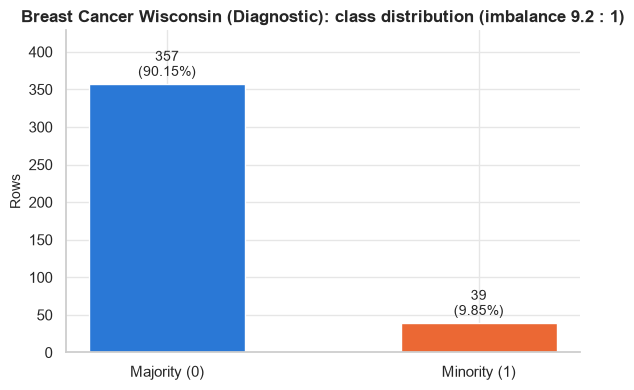

In [4]:
display(D.overview(df, spec))
PL.class_distribution(df, spec.title, PLOTS); plt.show()

,KS D (majority vs minority)
perimeter_worst,0.8959
radius_worst,0.8627
area_worst,0.8627
concave points_mean,0.8446
concave points_worst,0.8265
perimeter_mean,0.8199
concavity_mean,0.8134
radius_mean,0.8031
area_mean,0.8003
area_se,0.7481


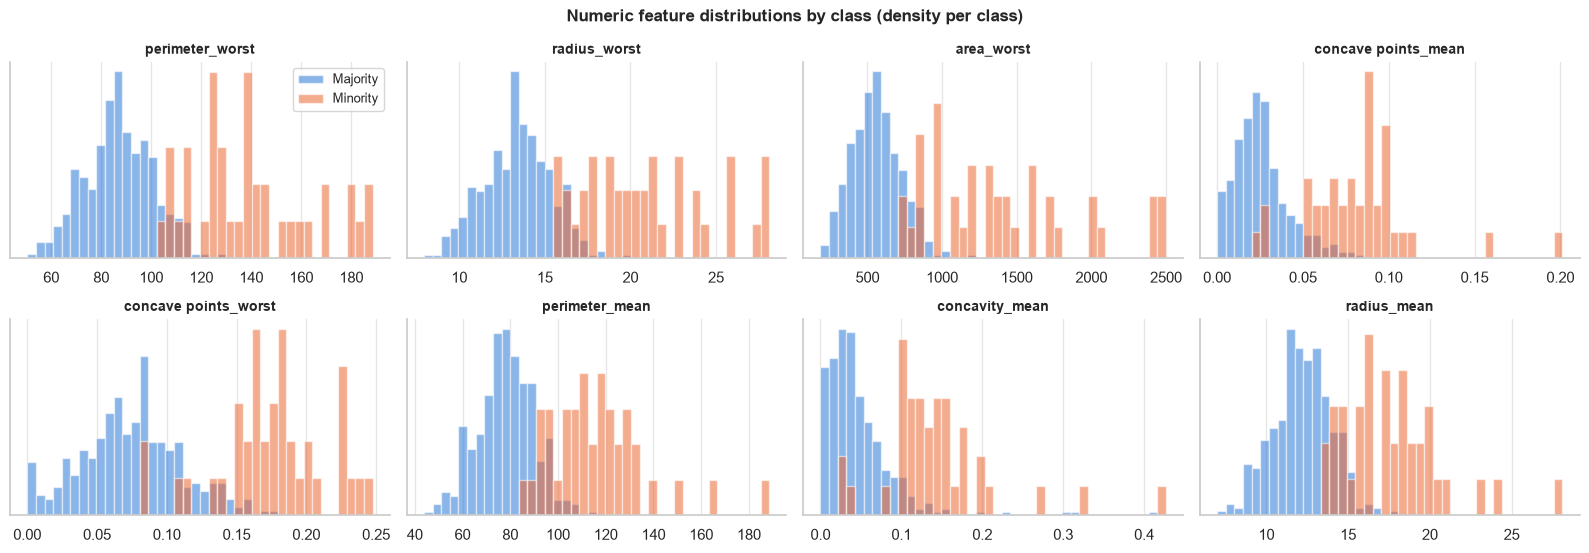

In [5]:
ks = D.ks_ranking(df, spec)
display(ks.head(10).to_frame("KS D (majority vs minority)"))
TOP_KS = list(ks.index[:8])
PL.feature_distributions(df, TOP_KS, PLOTS); plt.show()

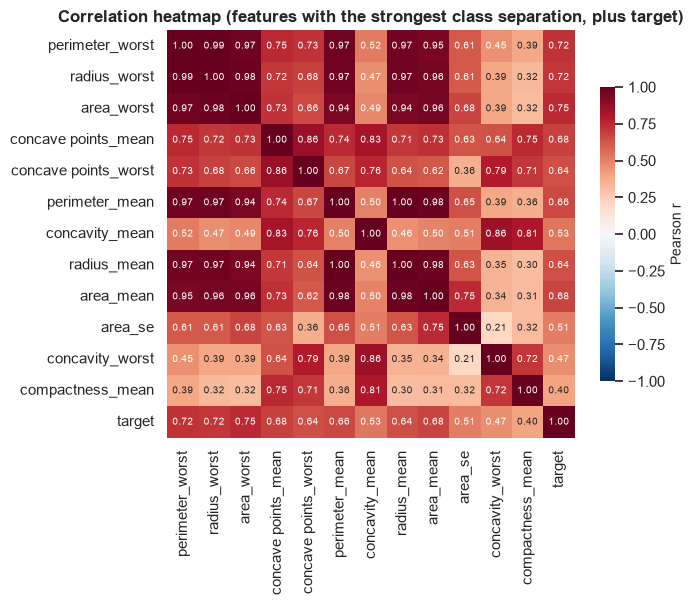

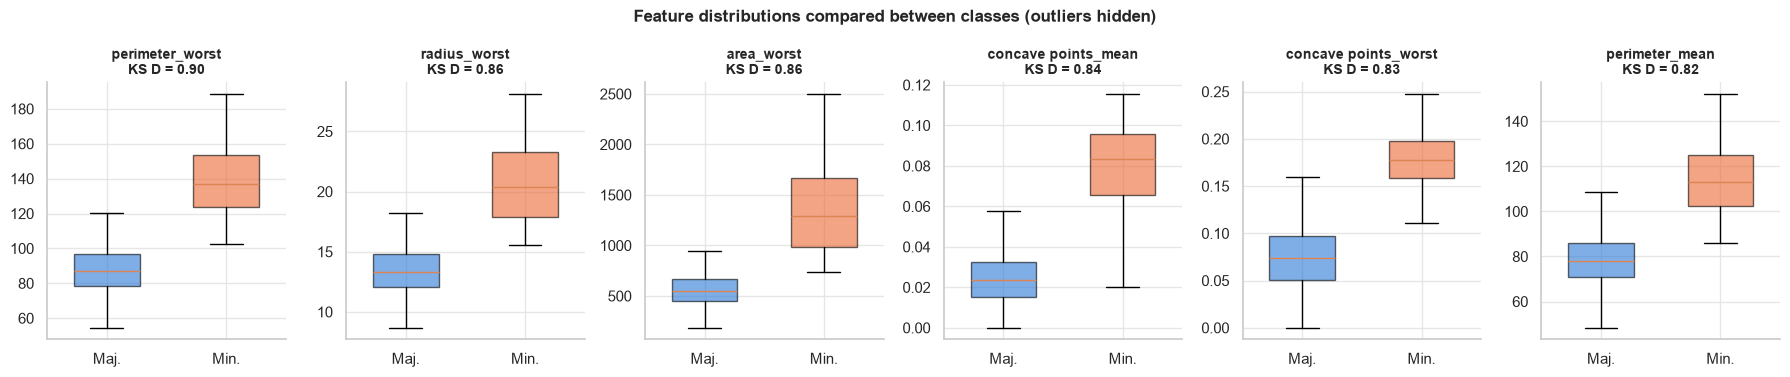

In [6]:
PL.correlation_heatmap(df, list(ks.index[:12]), PLOTS); plt.show()
PL.class_comparison(df, TOP_KS[:6], ks, PLOTS); plt.show()

## Stage 3: Leak-free preprocessing
```
full data --stratified 25%--> TEST (never resampled; used once, in Stage 6)
   └── DEVELOPMENT (75%) ── repeated stratified k-fold (Stage 5); in each fold, on the training part only:
                            impute + encode + scale  →  SHAP (inside the SHAP samplers)  →  oversample  →  fit model
```
Missing values: median (numeric) / most frequent (categorical) imputation. Categorical features are one-hot
encoded and numeric features are standardised. Every one of these steps is fitted on training rows only. The
table below shows the final fit on the whole development set: the scaler makes the development data exactly
mean 0, while the test set is only *close* to 0, because the test set was never used to fit anything.

In [7]:
dev_df, test_df = P.split_dev_test(df)
split = pd.DataFrame({"Rows": [len(dev_df), len(test_df)],
                      "Majority (0)": [int((dev_df.target == 0).sum()), int((test_df.target == 0).sum())],
                      "Minority (1)": [int(dev_df.target.sum()), int(test_df.target.sum())]},
                     index=["Development (75%)", "Hold-out test (25%)"])
split["Minority %"] = (split["Minority (1)"] / split["Rows"]).map("{:.2%}".format)
display(split)
assert not set(dev_df.index) & set(test_df.index), "development and test rows overlap"

pre = P.Preprocessor(spec).fit(dev_df)
print(f"Model space after encoding: {len(pre.feature_names_)} columns "
      f"({pre.n_numeric_} scaled numeric + {len(pre.feature_names_) - pre.n_numeric_} one-hot)")
display(pre.summary(dev_df, test_df).head(15))

,Rows,Majority (0),Minority (1),Minority %
Development (75%),297,268,29,9.76%
Hold-out test (25%),99,89,10,10.10%


Model space after encoding: 30 columns (30 scaled numeric + 0 one-hot)


,Kind,Missing (train),Imputation value (train median),Scaler mean (train),Scaler std (train),Train mean after,Test mean after
Feature,,,,,,,
radius_mean,numeric,0,12.4500,12.7176,2.6161,-0.0000,-0.0467
texture_mean,numeric,0,18.0200,18.3899,4.0128,-0.0000,-0.1725
perimeter_mean,numeric,0,79.7800,82.0202,17.7637,0.0000,-0.0483
area_mean,numeric,0,476.7000,519.3492,247.2972,-0.0000,-0.0662
smoothness_mean,numeric,0,0.0925,0.0928,0.0136,0.0000,0.1237
compactness_mean,numeric,0,0.0769,0.0847,0.0386,-0.0000,0.0456
concavity_mean,numeric,0,0.0406,0.0573,0.0589,-0.0000,-0.1040
concave points_mean,numeric,0,0.0258,0.0316,0.0255,0.0000,-0.0429
symmetry_mean,numeric,0,0.1735,0.1764,0.0251,-0.0000,-0.1377


## Stage 4: Oversampling and synthetic-sample inspection
The cell below fits **every sampler on the preprocessed development set** (the same chain is re-run inside every
CV fold in Stage 5) and fits the three downstream models on each resampled set. Test-set scores are only reported
in Stage 6.

All SMOTE-family methods share one generation engine (`src/oversampling/provenance.py`):
$x_{new} = x_a + \lambda (x_{nn} - x_a)$ with $\lambda \sim U(0,1)$, interpolated in the full, unweighted feature space.
They differ only in **which rows can be anchors** $x_a$ and **in which space the neighbour $x_{nn}$ is searched**.
They also share one random seed. For SMOTE, SHAP-Filtered SMOTE and SHAP-Weighted SMOTE (which all draw anchors
from every minority row), synthetic row *i* therefore has the same anchor, the same neighbour rank and the same
$\lambda$, so any difference between these three comes from neighbour selection alone. Borderline-SMOTE draws
from a smaller anchor pool, so its rows pair up differently. The engine records the parents, neighbour rank,
distance and $\lambda$ of every synthetic row.

No Sampling            sampled in    0.0 s, 3 models fitted and scored on the test set


Random Oversampling    sampled in    1.5 s, 3 models fitted and scored on the test set


SMOTE                  sampled in    0.1 s, 3 models fitted and scored on the test set


Borderline-SMOTE       sampled in    0.1 s, 3 models fitted and scored on the test set


SHAP-Filtered SMOTE    sampled in    0.3 s, 3 models fitted and scored on the test set


SHAP-Weighted SMOTE    sampled in    0.3 s, 3 models fitted and scored on the test set


,Anchor pool,Neighbour search space,Features in search,Search features (first 8),Synthetic rows
Method,,,,,
No Sampling,-,-,0,-,0
Random Oversampling,all minority rows,none (exact copies),0,-,239
SMOTE,all minority rows,all features (Euclidean),30,"radius_mean, texture_mean, perimeter_mean, are...",239
Borderline-SMOTE,DANGER rows only (7 of 29),all features (Euclidean),30,"radius_mean, texture_mean, perimeter_mean, are...",239
SHAP-Filtered SMOTE,all minority rows,17 SHAP-selected features (Euclidean),17,"radius_mean, perimeter_mean, area_mean, compac...",239
SHAP-Weighted SMOTE,all minority rows,"all features, column j scaled by sqrt(w_j)",30,"radius_mean, texture_mean, perimeter_mean, are...",239


,real_majority,real_minority,synthetic_minority,final_majority,final_minority,sampling_seconds
method,,,,,,
No Sampling,268,29,0,268,29,0.0108
Random Oversampling,268,29,239,268,268,1.4695
SMOTE,268,29,239,268,268,0.0598
Borderline-SMOTE,268,29,239,268,268,0.0630
SHAP-Filtered SMOTE,268,29,239,268,268,0.3120
SHAP-Weighted SMOTE,268,29,239,268,268,0.3156


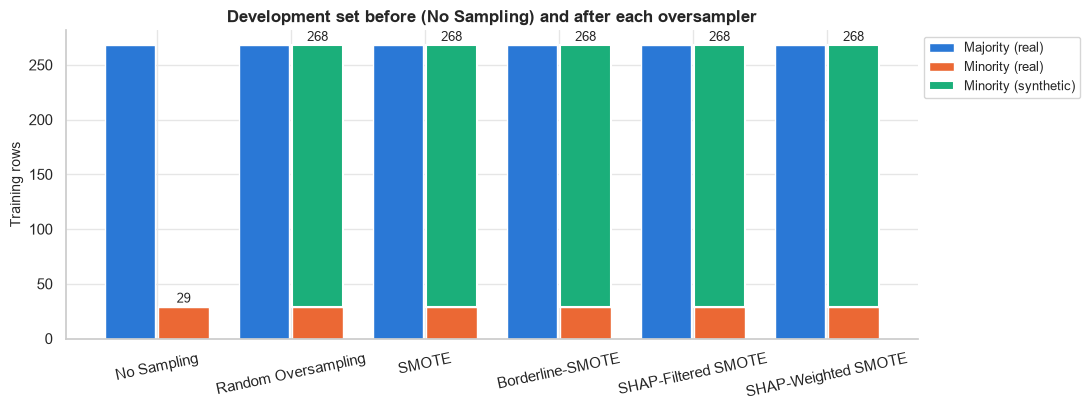

In [8]:
final = R.run_final(dev_df, test_df, spec)
display(I.search_space_description(final))
display(final.sampling)
PL.balanced_class_counts(final, PLOTS); plt.show()

### 4A. Neighbour identification
For each method: the k = 5 nearest minority neighbours of the first two minority seeds, the distance in the
method's search space, the plain Euclidean distance, the rank the same neighbour would have under plain SMOTE,
and the features that make up most of the search distance. For Borderline-SMOTE each seed is also labelled
SAFE / DANGER / NOISE from its 10 nearest neighbours in the whole training set; only DANGER rows can be anchors.

In [9]:
seed_ids = final.dev_row_ids[final.samplers["SMOTE"].minority_positions_[:2]]
for m in I.INTERPOLATING:
    t = I.neighbour_table(final, m, max_seeds=2)
    display(Markdown(f"**{m}**"))
    display(t.drop(columns="method"))
bl = final.samplers["Borderline-SMOTE"]
display(pd.Series({"SAFE": int(bl.safe_mask_.sum()), "DANGER (anchors)": int(bl.danger_mask_.sum()),
                   "NOISE": int(bl.noise_mask_.sum())}, name="Borderline-SMOTE seed status").to_frame())
display(I.neighbour_overlap_with_smote(final))

**SMOTE**

,seed_row_id,neighbour_rank,neighbour_row_id,search_distance,euclidean_distance,rank_under_plain_smote,top_features_in_search_distance
0,39,1,435,2.1801,2.1801,1,"concave points_worst (17%), texture_worst (16%..."
1,39,2,330,3.5893,3.5893,2,"texture_mean (14%), fractal_dimension_worst (9..."
2,39,3,255,3.8264,3.8264,3,"fractal_dimension_worst (23%), concave points_..."
3,39,4,253,5.0034,5.0034,4,"fractal_dimension_worst (12%), compactness_wor..."
4,39,5,408,5.3415,5.3415,5,"area_worst (11%), area_mean (11%), radius_wors..."
5,263,1,40,2.4200,2.4200,1,"symmetry_mean (15%), radius_mean (12%), area_m..."
6,263,2,132,5.3141,5.3141,2,"symmetry_mean (21%), compactness_mean (12%), s..."
7,263,3,253,5.3785,5.3785,3,"concave points_mean (16%), concave points_wors..."
8,263,4,317,5.7923,5.7923,4,"concave points_mean (12%), concave points_wors..."
9,263,5,255,5.9637,5.9637,5,"smoothness_mean (15%), smoothness_worst (12%),..."


**Borderline-SMOTE**

,seed_row_id,seed_status,majority_in_10_nn,neighbour_rank,neighbour_row_id,search_distance,euclidean_distance,rank_under_plain_smote,top_features_in_search_distance
0,39,DANGER,7,1,435,2.1801,2.1801,1,"concave points_worst (17%), texture_worst (16%..."
1,39,DANGER,7,2,330,3.5893,3.5893,2,"texture_mean (14%), fractal_dimension_worst (9..."
2,39,DANGER,7,3,255,3.8264,3.8264,3,"fractal_dimension_worst (23%), concave points_..."
3,39,DANGER,7,4,253,5.0034,5.0034,4,"fractal_dimension_worst (12%), compactness_wor..."
4,39,DANGER,7,5,408,5.3415,5.3415,5,"area_worst (11%), area_mean (11%), radius_wors..."
5,263,DANGER,9,1,40,2.4200,2.4200,1,"symmetry_mean (15%), radius_mean (12%), area_m..."
6,263,DANGER,9,2,132,5.3141,5.3141,2,"symmetry_mean (21%), compactness_mean (12%), s..."
7,263,DANGER,9,3,253,5.3785,5.3785,3,"concave points_mean (16%), concave points_wors..."
8,263,DANGER,9,4,317,5.7923,5.7923,4,"concave points_mean (12%), concave points_wors..."
9,263,DANGER,9,5,255,5.9637,5.9637,5,"smoothness_mean (15%), smoothness_worst (12%),..."


**SHAP-Filtered SMOTE**

,seed_row_id,neighbour_rank,neighbour_row_id,search_distance,euclidean_distance,rank_under_plain_smote,top_features_in_search_distance
0,39,1,435,1.5340,2.1801,1,"concave points_worst (34%), compactness_worst ..."
1,39,2,330,2.7470,3.5893,2,"radius_worst (14%), perimeter_mean (13%), area..."
2,39,3,255,2.7794,3.8264,3,"concave points_worst (43%), concavity_worst (1..."
3,39,4,15,3.5154,6.5005,10,"compactness_worst (33%), concavity_worst (11%)..."
4,39,5,132,4.0285,5.4570,6,"concave points_worst (23%), area_worst (10%), ..."
5,263,1,40,1.9455,2.4200,1,"radius_mean (18%), area_mean (17%), perimeter_..."
6,263,2,132,3.6302,5.3141,2,"compactness_mean (27%), smoothness_worst (17%)..."
7,263,3,255,4.1690,5.9637,5,"smoothness_worst (24%), compactness_mean (20%)..."
8,263,4,253,4.3627,5.3785,3,"concave points_mean (24%), concave points_wors..."
9,263,5,435,4.5586,6.0817,6,"smoothness_worst (30%), concave points_worst (..."


**SHAP-Weighted SMOTE**

,seed_row_id,neighbour_rank,neighbour_row_id,search_distance,euclidean_distance,rank_under_plain_smote,top_features_in_search_distance
0,39,1,435,0.4605,2.1801,1,"concave points_worst (53%), radius_worst (8%),..."
1,39,2,330,0.7479,3.5893,2,"area_worst (15%), radius_worst (15%), perimete..."
2,39,3,255,0.8033,3.8264,3,"concave points_worst (74%), concavity_worst (5..."
3,39,4,15,0.9185,6.5005,10,"concave points_worst (21%), compactness_worst ..."
4,39,5,253,1.0976,5.0034,4,"area_worst (15%), perimeter_worst (13%), radiu..."
5,263,1,40,0.5340,2.4200,1,"perimeter_worst (18%), concave points_worst (1..."
6,263,2,132,0.8246,5.3141,2,"concave points_worst (19%), concave points_mea..."
7,263,3,255,0.8824,5.9637,5,"concave points_worst (21%), compactness_mean (..."
8,263,4,435,1.1253,6.0817,6,"concave points_worst (45%), concave points_mea..."
9,263,5,253,1.2174,5.3785,3,"concave points_worst (41%), concave points_mea..."


,Borderline-SMOTE seed status
SAFE,21
DANGER (anchors),7
NOISE,1


,mean_jaccard_with_SMOTE_neighbours,seeds_with_identical_neighbours
method,,
SMOTE,1.0000,1.0000
Borderline-SMOTE,1.0000,1.0000
SHAP-Filtered SMOTE,0.6921,0.3103
SHAP-Weighted SMOTE,0.6095,0.1034


### 4B. Synthetic sample generation
Below are the first synthetic records of each method, with their two parents (original row ids), $\lambda$ and
neighbour rank, followed by a feature-by-feature walk through synthetic row #0 of every interpolating method.
Because of the shared seed, row #0 of SMOTE, SHAP-Filtered and SHAP-Weighted SMOTE has the same anchor and the
same $\lambda$, so you can see how the choice of neighbour changes the result (Borderline-SMOTE's anchor comes
from its DANGER pool). A Random Oversampling record is an exact copy of parent 1.

In [10]:
for m in C.OVERSAMPLERS:
    rec = I.generation_records(final, m)
    display(Markdown(f"**{m}**: {len(rec):,} synthetic rows"))
    display(rec.head(4).iloc[:, :14])

**Random Oversampling**: 239 synthetic rows

,synthetic_id,method,parent_1_row_id,parent_2_row_id,neighbour_rank,lambda,search_distance,target,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean
0,1-0,Random Oversampling,132,NaN,NaN,NaN,NaN,1,16.1600,21.5400,106.2000,809.8000,0.1008,0.1284
1,1-1,Random Oversampling,335,NaN,NaN,NaN,NaN,1,17.0600,21.0000,111.8000,918.6000,0.1119,0.1056
2,1-2,Random Oversampling,17,NaN,NaN,NaN,NaN,1,16.1300,20.6800,108.1000,798.8000,0.1170,0.2022
3,1-3,Random Oversampling,365,NaN,NaN,NaN,NaN,1,20.4400,21.7800,133.8000,"1,293.0000",0.0915,0.1131


**SMOTE**: 239 synthetic rows

,synthetic_id,method,parent_1_row_id,parent_2_row_id,neighbour_rank,lambda,search_distance,target,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean
0,2-0,SMOTE,370,330.0000,4,0.4389,5.9854,1,16.2096,19.8755,107.5956,819.6849,0.0963,0.1442
1,2-1,SMOTE,255,253.0000,5,0.6974,3.9838,1,16.2892,17.0709,106.4722,829.6025,0.1035,0.1113
2,2-2,SMOTE,435,39.0000,1,0.9756,2.1801,1,13.4922,20.7907,88.4663,560.1824,0.1017,0.1252
3,2-3,SMOTE,262,335.0000,4,0.7861,4.7778,1,17.1092,21.2417,112.3562,924.8469,0.1072,0.1102


**Borderline-SMOTE**: 239 synthetic rows

,synthetic_id,method,parent_1_row_id,parent_2_row_id,neighbour_rank,lambda,search_distance,target,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean
0,3-0,Borderline-SMOTE,39,253.0000,4,0.4389,5.0034,1,15.1565,19.1786,99.1964,721.1461,0.1012,0.1161
1,3-1,Borderline-SMOTE,253,255.0000,5,0.6974,3.9838,1,14.9708,17.0591,97.9578,700.9975,0.1069,0.1207
2,3-2,Borderline-SMOTE,263,40.0000,1,0.9756,2.4200,1,13.4929,21.5264,86.5169,567.7683,0.0815,0.0602
3,3-3,Borderline-SMOTE,430,39.0000,4,0.7861,6.8398,1,13.7838,21.1858,91.3309,586.1131,0.1011,0.1463


**SHAP-Filtered SMOTE**: 239 synthetic rows

,synthetic_id,method,parent_1_row_id,parent_2_row_id,neighbour_rank,lambda,search_distance,target,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean
0,4-0,SHAP-Filtered SMOTE,370,408.0000,4,0.4389,4.0460,1,17.0698,22.1357,112.8621,906.8023,0.1001,0.1412
1,4-1,SHAP-Filtered SMOTE,255,253.0000,5,0.6974,3.6820,1,16.2892,17.0709,106.4722,829.6025,0.1035,0.1113
2,4-2,SHAP-Filtered SMOTE,435,39.0000,1,0.9756,1.5340,1,13.4922,20.7907,88.4663,560.1824,0.1017,0.1252
3,4-3,SHAP-Filtered SMOTE,262,335.0000,4,0.7861,2.8166,1,17.1092,21.2417,112.3562,924.8469,0.1072,0.1102


**SHAP-Weighted SMOTE**: 239 synthetic rows

,synthetic_id,method,parent_1_row_id,parent_2_row_id,neighbour_rank,lambda,search_distance,target,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean
0,5-0,SHAP-Weighted SMOTE,370,408.0000,4,0.4389,0.7923,1,17.0698,22.1357,112.8621,906.8023,0.1001,0.1412
1,5-1,SHAP-Weighted SMOTE,255,39.0000,5,0.6974,0.8033,1,13.6253,19.6791,89.3170,572.2737,0.1040,0.1262
2,5-2,SHAP-Weighted SMOTE,435,39.0000,1,0.9756,0.4605,1,13.4922,20.7907,88.4663,560.1824,0.1017,0.1252
3,5-3,SHAP-Weighted SMOTE,262,85.0000,4,0.7861,0.6559,1,18.2097,19.2923,119.6666,"1,047.7874",0.0969,0.1100


In [11]:
for m in I.INTERPOLATING:
    if final.samplers[m].n_synthetic_ == 0:
        continue
    ex = I.example_walkthrough(final, m, 0, max_features=8)
    display(Markdown(f"**{ex.attrs['header']}**"))
    display(ex)

**SMOTE: synthetic #0 = parent_1 (row 370) + 0.4389 x (parent_2 (row 330) - parent_1); parent_2 is neighbour rank 4 in the search space**

,parent_1,parent_2,gap (p2 - p1),lambda x gap,synthetic
feature,,,,,
radius_mean,16.3500,16.0300,-0.3200,-0.1404,16.2096
texture_mean,23.2900,15.5100,-7.7800,-3.4145,19.8755
perimeter_mean,109.0000,105.8000,-3.2000,-1.4044,107.5956
area_mean,840.4000,793.2000,-47.2000,-20.7151,819.6849
smoothness_mean,0.0974,0.0949,-0.0025,-0.0011,0.0963
compactness_mean,0.1497,0.1371,-0.0126,-0.0055,0.1442
concavity_mean,0.1811,0.1204,-0.0607,-0.0266,0.1545
concave points_mean,0.0877,0.0704,-0.0173,-0.0076,0.0801


**Borderline-SMOTE: synthetic #0 = parent_1 (row 39) + 0.4389 x (parent_2 (row 253) - parent_1); parent_2 is neighbour rank 4 in the search space**

,parent_1,parent_2,gap (p2 - p1),lambda x gap,synthetic
feature,,,,,
radius_mean,13.4800,17.3000,3.8200,1.6765,15.1565
texture_mean,20.8200,17.0800,-3.7400,-1.6414,19.1786
perimeter_mean,88.4000,113.0000,24.6000,10.7964,99.1964
area_mean,559.2000,928.2000,369.0000,161.9461,721.1461
smoothness_mean,0.1016,0.1008,-0.0008,-0.0004,0.1012
compactness_mean,0.1255,0.1041,-0.0214,-0.0094,0.1161
concavity_mean,0.1063,0.1266,0.0203,0.0089,0.1152
concave points_mean,0.0544,0.0835,0.0291,0.0128,0.0672


**SHAP-Filtered SMOTE: synthetic #0 = parent_1 (row 370) + 0.4389 x (parent_2 (row 408) - parent_1); parent_2 is neighbour rank 4 in the search space**

,parent_1,parent_2,gap (p2 - p1),lambda x gap,synthetic,SHAP weight w_j
feature,,,,,,
concave points_worst,0.2248,0.1974,-0.0274,-0.0120,0.2128,0.1432
perimeter_worst,129.3000,138.1000,8.8000,3.8621,133.1621,0.1351
area_worst,"1,165.0000","1,349.0000",184.0000,80.7536,"1,245.7536",0.0887
concave points_mean,0.0877,0.0882,0.0005,0.0002,0.0880,0.0820
radius_worst,19.3800,21.0800,1.7000,0.7461,20.1261,0.0792
perimeter_mean,109.0000,117.8000,8.8000,3.8621,112.8621,0.0617
area_mean,840.4000,991.7000,151.3000,66.4023,906.8023,0.0578
radius_mean,16.3500,17.9900,1.6400,0.7198,17.0698,0.0442


**SHAP-Weighted SMOTE: synthetic #0 = parent_1 (row 370) + 0.4389 x (parent_2 (row 408) - parent_1); parent_2 is neighbour rank 4 in the search space**

,parent_1,parent_2,gap (p2 - p1),lambda x gap,synthetic,SHAP weight w_j
feature,,,,,,
concave points_worst,0.2248,0.1974,-0.0274,-0.0120,0.2128,0.1432
perimeter_worst,129.3000,138.1000,8.8000,3.8621,133.1621,0.1351
area_worst,"1,165.0000","1,349.0000",184.0000,80.7536,"1,245.7536",0.0887
concave points_mean,0.0877,0.0882,0.0005,0.0002,0.0880,0.0820
radius_worst,19.3800,21.0800,1.7000,0.7461,20.1261,0.0792
perimeter_mean,109.0000,117.8000,8.8000,3.8621,112.8621,0.0617
area_mean,840.4000,991.7000,151.3000,66.4023,906.8023,0.0578
radius_mean,16.3500,17.9900,1.6400,0.7198,17.0698,0.0442


### 4C. SHAP guidance
Both proposed methods first fit a preliminary Random Forest (50 trees, depth 5) **on the training data only**,
explain it with `shap.TreeExplainer`, and turn the mean absolute SHAP value of each feature (MASV) into a weight
$w_j = \text{MASV}_j / \sum_k \text{MASV}_k$.
* **SHAP-Filtered SMOTE** searches neighbours only on the top features whose cumulative weight reaches 90%.
* **SHAP-Weighted SMOTE** multiplies every column by $\sqrt{w_j}$ before the Euclidean search, so the distance becomes
  $d_W(a,b)=\sqrt{\sum_j w_j (a_j-b_j)^2}$: high-SHAP features decide who counts as a neighbour.

The rationale tables show, for the first synthetic rows, the neighbour's rank in SHAP space and under plain SMOTE,
which features made up the SHAP distance, and how similar the two parents' SHAP explanations are (cosine).

,rank,MASV,weight_w,cumulative_weight,sqrt_w_stretch_vs_uniform,kept_by_SHAP_Filtered
concave points_worst,1,0.0280,0.1432,0.1432,2.0727,True
perimeter_worst,2,0.0264,0.1351,0.2783,2.0131,True
area_worst,3,0.0173,0.0887,0.3670,1.6316,True
concave points_mean,4,0.0160,0.0820,0.4490,1.5682,True
radius_worst,5,0.0155,0.0792,0.5282,1.5412,True
perimeter_mean,6,0.0121,0.0617,0.5899,1.3605,True
area_mean,7,0.0113,0.0578,0.6476,1.3164,True
radius_mean,8,0.0086,0.0442,0.6918,1.1510,True
concavity_mean,9,0.0083,0.0426,0.7344,1.1310,True
concavity_worst,10,0.0060,0.0305,0.7649,0.9565,True


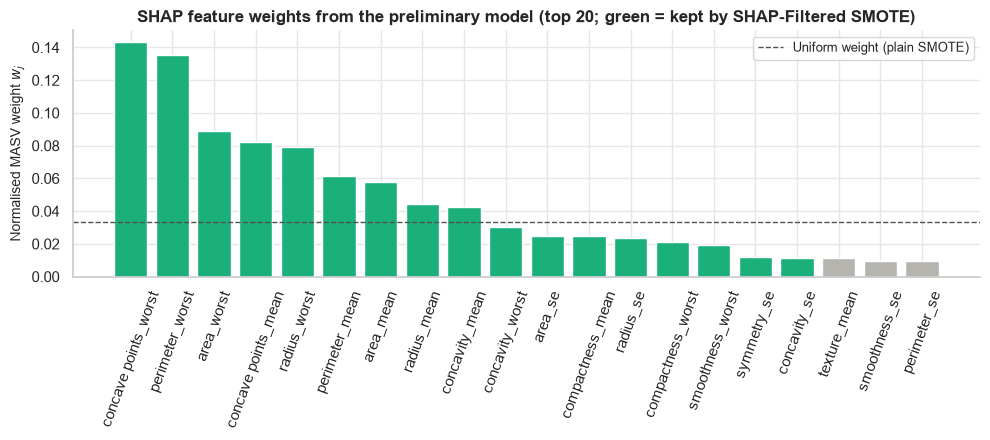

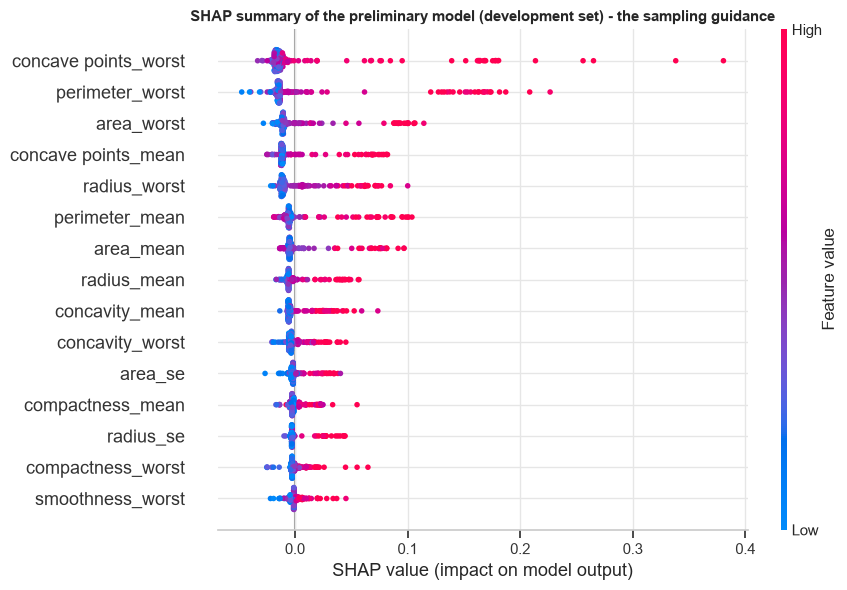

In [12]:
weights = I.shap_weight_table(final)
display(weights.head(15))
PL.masv_weights(weights, PLOTS); plt.show()
PL.shap_summary(final, PLOTS); plt.show()

In [13]:
for m in C.PROPOSED_METHODS:
    r = I.shap_rationale(final, m, n=8)
    display(Markdown(f"**{m}: neighbour-selection rationale (first 8 synthetic rows)**"))
    display(r)
    moved = (~r["would_plain_SMOTE_consider_it"]).mean()
    print(f"{moved:.0%} of these parent pairs would NOT be neighbours under plain SMOTE")
display(Markdown("**SHAP-Weighted SMOTE, synthetic row #0: parents' SHAP values on the highest-weight features**"))
display(I.parent_shap_detail(final, "SHAP-Weighted SMOTE", 0))

**SHAP-Filtered SMOTE: neighbour-selection rationale (first 8 synthetic rows)**

,parent_1_row_id,parent_2_row_id,lambda,rank_in_SHAP_space,rank_under_plain_SMOTE,parents_SHAP_cosine,distance_made_of,SHAP p1/p2 [concave points_worst],SHAP p1/p2 [perimeter_worst],SHAP p1/p2 [area_worst],would_plain_SMOTE_consider_it
synthetic_index,,,,,,,,,,,
0,370,408,0.4389,4,3,0.9920,"symmetry_se (39%), concavity_worst (30%), conc...",+0.181 / +0.169,+0.156 / +0.163,+0.079 / +0.092,True
1,255,253,0.6974,5,5,0.3490,"area_mean (13%), radius_mean (12%), concave po...",+0.014 / +0.167,-0.002 / +0.168,+0.034 / +0.094,True
2,435,39,0.9756,1,1,0.9810,"concave points_worst (34%), compactness_worst ...",+0.338 / +0.381,+0.010 / +0.006,+0.022 / +0.003,True
3,262,335,0.7861,4,4,0.8750,"smoothness_worst (28%), symmetry_se (21%), con...",+0.046 / +0.163,+0.209 / +0.138,+0.107 / +0.089,True
4,365,565,0.4504,1,7,0.9640,"radius_se (17%), concave points_mean (14%), co...",+0.139 / +0.076,+0.182 / +0.167,+0.092 / +0.106,False
5,365,85,0.9268,2,8,0.9550,"symmetry_se (31%), area_mean (14%), radius_mea...",+0.139 / +0.068,+0.182 / +0.168,+0.092 / +0.098,False
6,408,132,0.8228,4,4,0.7450,"concave points_worst (30%), concave points_mea...",+0.169 / -0.007,+0.163 / +0.227,+0.092 / +0.114,True
7,164,365,0.2272,3,3,0.9700,"area_worst (21%), area_mean (16%), concave poi...",+0.176 / +0.139,+0.132 / +0.182,+0.092 / +0.092,True


25% of these parent pairs would NOT be neighbours under plain SMOTE


**SHAP-Weighted SMOTE: neighbour-selection rationale (first 8 synthetic rows)**

,parent_1_row_id,parent_2_row_id,lambda,rank_in_SHAP_space,rank_under_plain_SMOTE,parents_SHAP_cosine,distance_made_of,SHAP p1/p2 [concave points_worst],SHAP p1/p2 [perimeter_worst],SHAP p1/p2 [area_worst],would_plain_SMOTE_consider_it
synthetic_index,,,,,,,,,,,
0,370,408,0.4389,4,3,0.9920,"concavity_worst (24%), symmetry_worst (20%), s...",+0.181 / +0.169,+0.156 / +0.163,+0.079 / +0.092,True
1,255,39,0.6974,5,4,0.2440,"concave points_worst (74%), concavity_worst (5...",+0.014 / +0.381,-0.002 / +0.006,+0.034 / +0.003,True
2,435,39,0.9756,1,1,0.9810,"concave points_worst (53%), radius_worst (8%),...",+0.338 / +0.381,+0.010 / +0.006,+0.022 / +0.003,True
3,262,85,0.7861,4,3,0.9720,"area_worst (17%), perimeter_worst (13%), radiu...",+0.046 / +0.068,+0.209 / +0.168,+0.107 / +0.098,True
4,365,565,0.4504,1,7,0.9640,"concave points_mean (19%), texture_se (13%), t...",+0.139 / +0.076,+0.182 / +0.167,+0.092 / +0.106,False
5,365,85,0.9268,2,8,0.9550,"symmetry_worst (14%), area_mean (13%), perimet...",+0.139 / +0.068,+0.182 / +0.168,+0.092 / +0.098,False
6,408,498,0.8228,4,5,0.9320,"concave points_worst (18%), radius_se (17%), a...",+0.169 / +0.077,+0.163 / +0.174,+0.092 / +0.100,True
7,164,365,0.2272,3,3,0.9700,"area_worst (25%), concave points_worst (17%), ...",+0.176 / +0.139,+0.132 / +0.182,+0.092 / +0.092,True


25% of these parent pairs would NOT be neighbours under plain SMOTE


**SHAP-Weighted SMOTE, synthetic row #0: parents' SHAP values on the highest-weight features**

,SHAP weight w_j,in search space,share of search distance,SHAP parent 1,SHAP parent 2,value parent 1 (scaled),value parent 2 (scaled),synthetic (scaled)
feature,,,,,,,,
concave points_worst,0.1432,True,0.0727,0.1809,0.1686,2.8582,2.2936,2.6104
perimeter_worst,0.1351,True,0.0347,0.1560,0.1634,1.6788,2.0805,1.8551
area_worst,0.0887,True,0.0421,0.0790,0.0915,1.5392,2.0851,1.7788
concave points_mean,0.0820,True,0.0001,0.0687,0.0781,2.2022,2.2222,2.2109
radius_worst,0.0792,True,0.0359,0.0581,0.0630,1.6357,2.1695,1.8700
perimeter_mean,0.0617,True,0.0241,0.0801,0.0728,1.5188,2.0142,1.7362
area_mean,0.0578,True,0.0344,0.0681,0.0747,1.2982,1.9101,1.5668
radius_mean,0.0442,True,0.0276,0.0305,0.0399,1.3885,2.0154,1.6636
concavity_mean,0.0426,True,0.0728,0.0371,0.0263,2.1006,1.0655,1.6463


### 4D. Quality of the synthetic samples
* **majority_share_in_5nn**: share of majority rows among the 5 nearest real development rows of each synthetic
  row. Higher means more synthetic points sit in majority territory, a proxy for label noise. The real
  minority rows give the reference value.
* **Fidelity** of synthetic vs real minority rows: marginal Wasserstein distance, KS-test pass rate and
  correlation-matrix similarity (does the synthetic data keep the real feature relationships?).
* **parents_SHAP_cosine_mean**: how similar the explanations of the two parents are.
* **detectability_auc_all / _numeric**: cross-validated ROC-AUC of a Random Forest trained to tell real minority rows
  from synthetic ones (0.5 = indistinguishable, 1 = trivially separable), on all model columns and on the numeric
  columns only. **fractional_onehot_cols_per_row** counts one-hot columns that interpolation left between 0 and 1
  (datasets with categorical features only). A detectable synthetic class can teach a model an artefact that never
  appears in real test rows.

,synthetic_rows,majority_share_in_5nn,synthetic_with_majority_nn1_%,mean_wasserstein_distance,max_wasserstein_distance,ks_test_pass_ratio,covariance_frobenius_dist,correlation_matrix_similarity,parents_SHAP_cosine_mean,distinct_parent_pairs,detectability_auc_all,detectability_auc_numeric
method,,,,,,,,,,,,
Real minority (reference),0,0.2207,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Random Oversampling,239,0.1632,0.0000,0.0595,0.1080,1.0000,2.7518,0.9961,NaN,NaN,NaN,NaN
SMOTE,239,0.1213,0.0000,0.1864,0.2979,1.0000,14.8266,0.9821,0.8353,118.0000,0.5258,0.5258
Borderline-SMOTE,239,0.3615,5.0209,0.6074,1.5130,0.4333,31.3346,0.7080,0.7009,35.0000,0.7556,0.7556
SHAP-Filtered SMOTE,239,0.1238,0.4184,0.1748,0.2844,1.0000,14.4818,0.9788,0.8473,118.0000,0.5172,0.5172
SHAP-Weighted SMOTE,239,0.1280,0.8368,0.1794,0.2934,1.0000,14.6886,0.9843,0.8586,118.0000,0.5362,0.5362


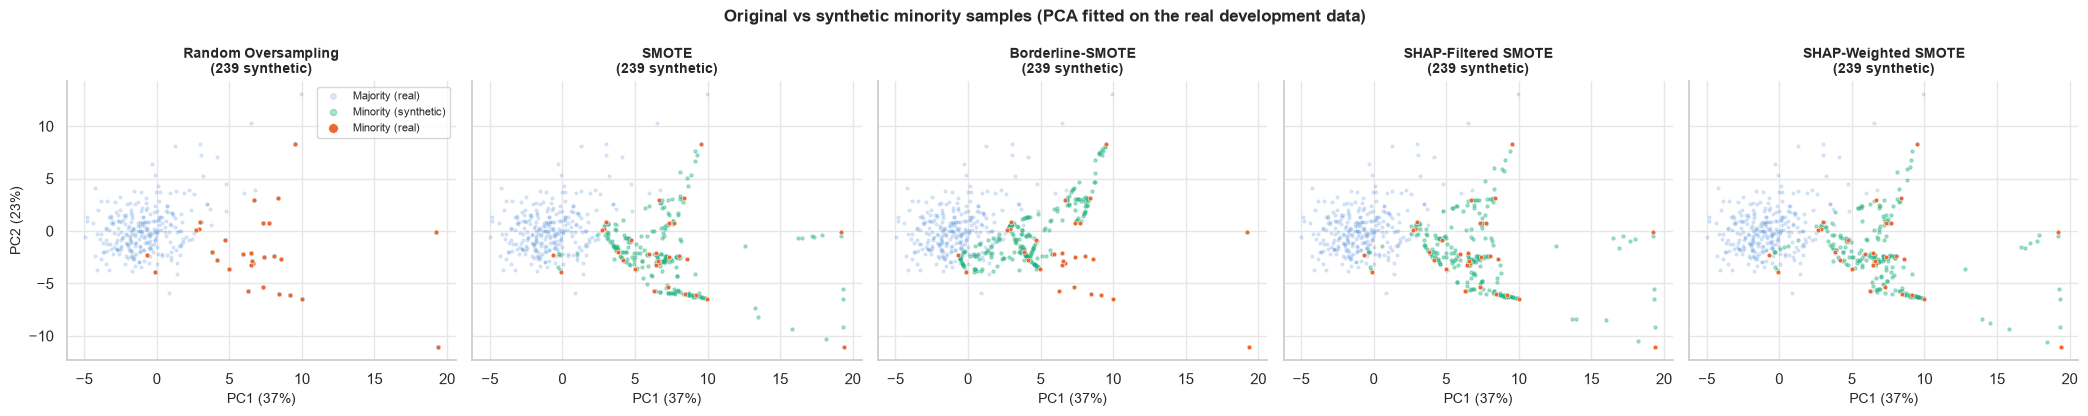

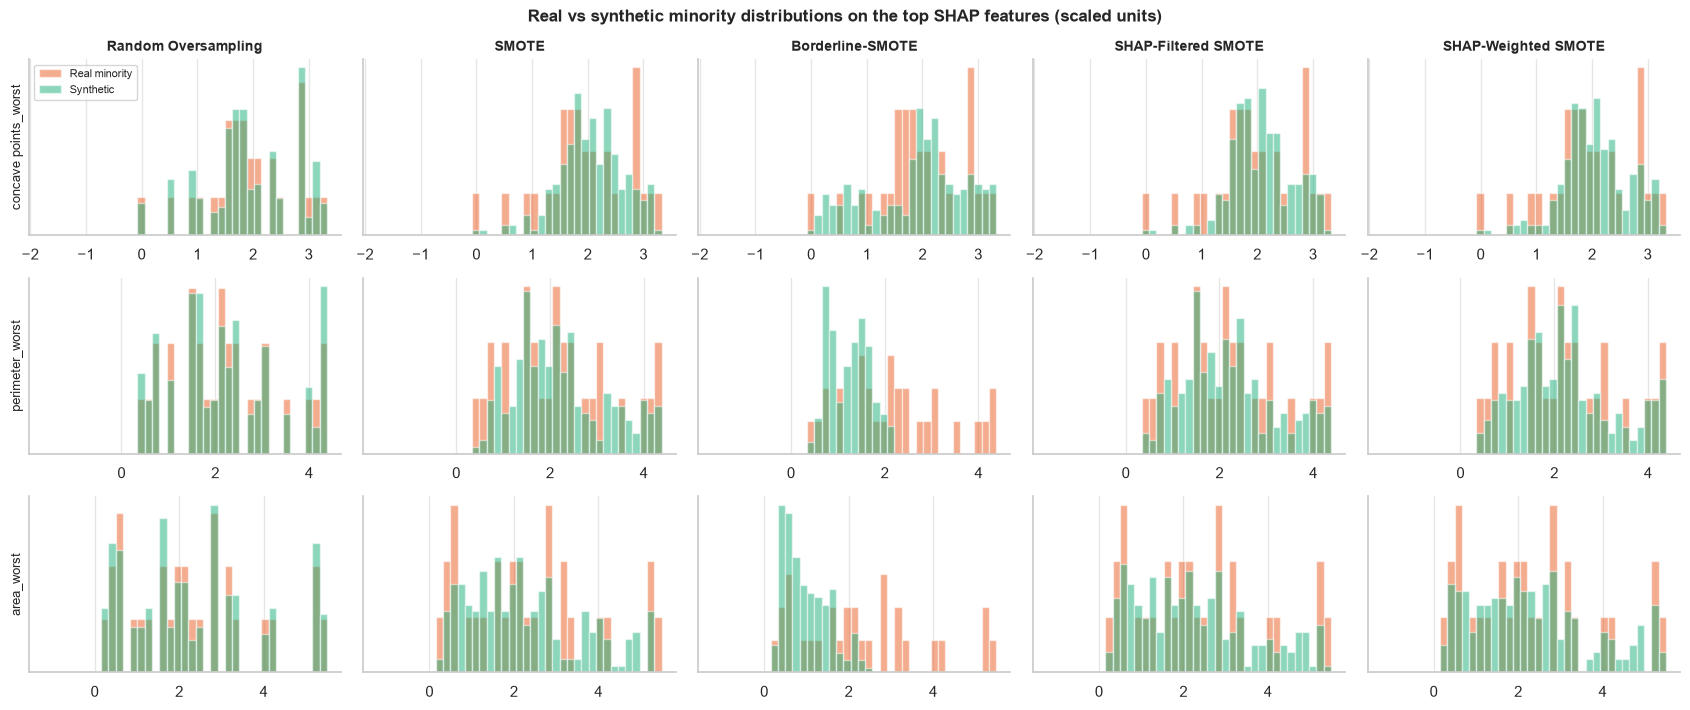

In [14]:
quality_tbl = I.synthetic_quality(final)
display(quality_tbl)
PL.pca_synthetic(final, PLOTS); plt.show()
PL.synthetic_feature_distributions(final, list(weights.index[:3]), PLOTS); plt.show()

In [15]:
files = O.save_sampling_artifacts(DIRS, final)
display(files)

,method,content,rows,file
0,Random Oversampling,synthetic samples,239,results/breast_cancer/synthetic_samples/random...
1,SMOTE,synthetic samples,239,results/breast_cancer/synthetic_samples/smote_...
2,SMOTE,neighbours,145,results/breast_cancer/neighbour_analysis/smote...
3,Borderline-SMOTE,synthetic samples,239,results/breast_cancer/synthetic_samples/border...
4,Borderline-SMOTE,neighbours,145,results/breast_cancer/neighbour_analysis/borde...
5,SHAP-Filtered SMOTE,synthetic samples,239,results/breast_cancer/synthetic_samples/shap_f...
6,SHAP-Filtered SMOTE,neighbours,145,results/breast_cancer/neighbour_analysis/shap_...
7,SHAP-Weighted SMOTE,synthetic samples,239,results/breast_cancer/synthetic_samples/shap_w...
8,SHAP-Weighted SMOTE,neighbours,145,results/breast_cancer/neighbour_analysis/shap_...
9,SHAP-Filtered SMOTE,"SHAP rationale (first 2,000 rows)",239,results/breast_cancer/neighbour_analysis/shap_...


## Stage 5: Repeated stratified cross-validation (leak-free)
For each of the 2 × 5 folds of the development set, the full chain (preprocessing → SHAP → oversampling → model) is
re-fitted on the training part with fresh objects, and scored on the untouched validation part. This gives a
mean ± standard deviation for every (method, model) pair, plus paired per-fold comparisons.

In [16]:
cv = R.run_cross_validation(dev_df, spec)
print(f"Cross-validation finished in {cv.elapsed_s / 60:.1f} min")

fold  1/10 done in    9.3 s


fold  2/10 done in    8.3 s


fold  3/10 done in    6.7 s


fold  4/10 done in    5.6 s


fold  5/10 done in    8.6 s


fold  6/10 done in    7.9 s


fold  7/10 done in    7.3 s


fold  8/10 done in    8.0 s


fold  9/10 done in    8.0 s


fold 10/10 done in    7.5 s
Cross-validation finished in 1.3 min


In [17]:
for model in C.MODEL_ORDER:
    display(Markdown(f"**{model}: cross-validation, mean ± sd over {C.CV_SPLITS * C.CV_REPEATS} folds**"))
    display(S.cv_comparison_table(cv, model))

**Logistic Regression: cross-validation, mean ± sd over 10 folds**

,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,Specificity
Sampling Method,,,,,,,
No Sampling,0.987 ± 0.013,1.0 ± 0.0,0.86 ± 0.144,0.919 ± 0.088,0.994 ± 0.01,0.961 ± 0.058,1.0 ± 0.0
Random Oversampling,0.968 ± 0.023,0.799 ± 0.143,0.91 ± 0.134,0.845 ± 0.122,0.995 ± 0.008,0.962 ± 0.056,0.974 ± 0.02
SMOTE,0.976 ± 0.021,0.878 ± 0.143,0.893 ± 0.132,0.878 ± 0.115,0.994 ± 0.011,0.962 ± 0.063,0.985 ± 0.019
Borderline-SMOTE,0.963 ± 0.026,0.788 ± 0.183,0.893 ± 0.132,0.826 ± 0.129,0.991 ± 0.012,0.952 ± 0.062,0.97 ± 0.026
SHAP-Filtered SMOTE,0.975 ± 0.021,0.871 ± 0.15,0.893 ± 0.132,0.872 ± 0.112,0.994 ± 0.011,0.962 ± 0.063,0.983 ± 0.022
SHAP-Weighted SMOTE,0.973 ± 0.018,0.849 ± 0.128,0.893 ± 0.132,0.863 ± 0.1,0.994 ± 0.012,0.962 ± 0.065,0.981 ± 0.017


**Random Forest: cross-validation, mean ± sd over 10 folds**

,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,Specificity
Sampling Method,,,,,,,
No Sampling,0.978 ± 0.018,0.963 ± 0.078,0.81 ± 0.155,0.873 ± 0.105,0.963 ± 0.059,0.916 ± 0.109,0.996 ± 0.008
Random Oversampling,0.978 ± 0.018,0.958 ± 0.09,0.827 ± 0.184,0.873 ± 0.113,0.989 ± 0.012,0.936 ± 0.068,0.994 ± 0.013
SMOTE,0.976 ± 0.014,0.93 ± 0.117,0.843 ± 0.156,0.869 ± 0.084,0.982 ± 0.024,0.927 ± 0.091,0.991 ± 0.016
Borderline-SMOTE,0.97 ± 0.015,0.875 ± 0.114,0.827 ± 0.166,0.836 ± 0.09,0.989 ± 0.014,0.946 ± 0.061,0.985 ± 0.015
SHAP-Filtered SMOTE,0.978 ± 0.016,0.942 ± 0.097,0.843 ± 0.156,0.878 ± 0.093,0.983 ± 0.022,0.922 ± 0.089,0.993 ± 0.013
SHAP-Weighted SMOTE,0.973 ± 0.016,0.91 ± 0.12,0.827 ± 0.166,0.851 ± 0.094,0.971 ± 0.047,0.909 ± 0.099,0.989 ± 0.016


**XGBoost: cross-validation, mean ± sd over 10 folds**

,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,Specificity
Sampling Method,,,,,,,
No Sampling,0.982 ± 0.015,0.969 ± 0.065,0.843 ± 0.156,0.892 ± 0.093,0.985 ± 0.018,0.927 ± 0.082,0.996 ± 0.008
Random Oversampling,0.976 ± 0.023,0.927 ± 0.155,0.843 ± 0.156,0.873 ± 0.126,0.981 ± 0.024,0.925 ± 0.092,0.991 ± 0.02
SMOTE,0.966 ± 0.025,0.839 ± 0.18,0.843 ± 0.156,0.829 ± 0.131,0.982 ± 0.023,0.922 ± 0.091,0.98 ± 0.024
Borderline-SMOTE,0.965 ± 0.02,0.847 ± 0.157,0.827 ± 0.146,0.82 ± 0.096,0.986 ± 0.019,0.929 ± 0.086,0.979 ± 0.024
SHAP-Filtered SMOTE,0.97 ± 0.025,0.858 ± 0.17,0.843 ± 0.156,0.841 ± 0.134,0.984 ± 0.019,0.927 ± 0.085,0.983 ± 0.02
SHAP-Weighted SMOTE,0.968 ± 0.024,0.836 ± 0.155,0.843 ± 0.156,0.834 ± 0.134,0.983 ± 0.02,0.924 ± 0.088,0.981 ± 0.017


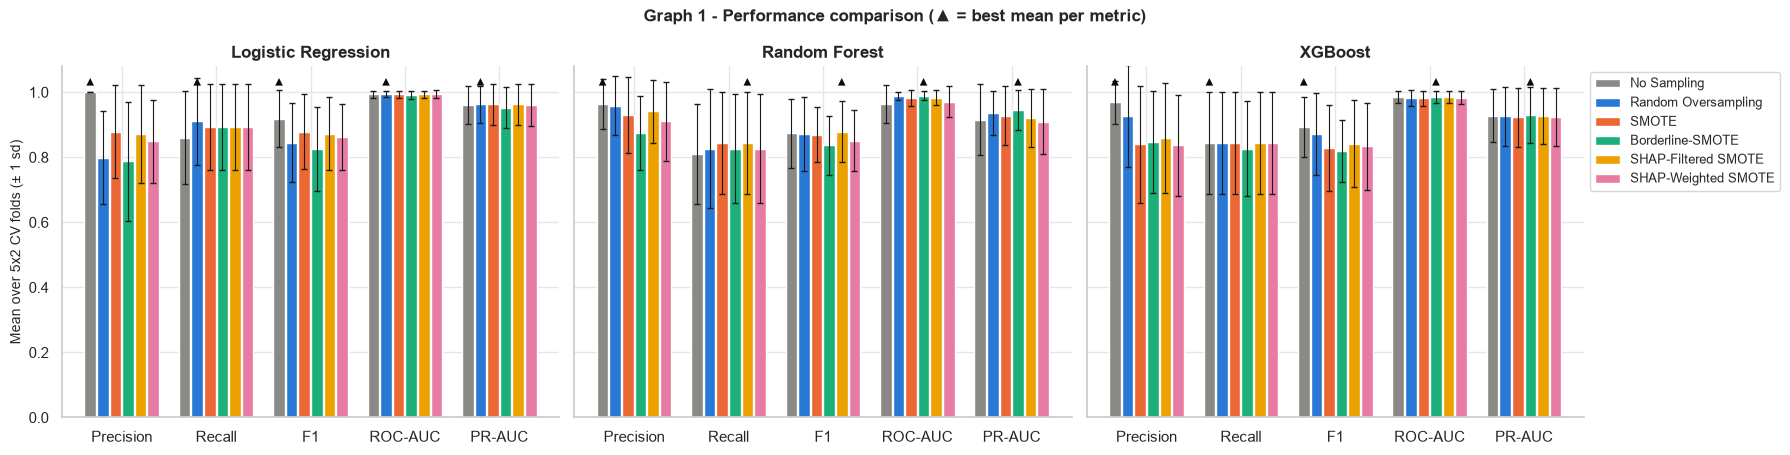

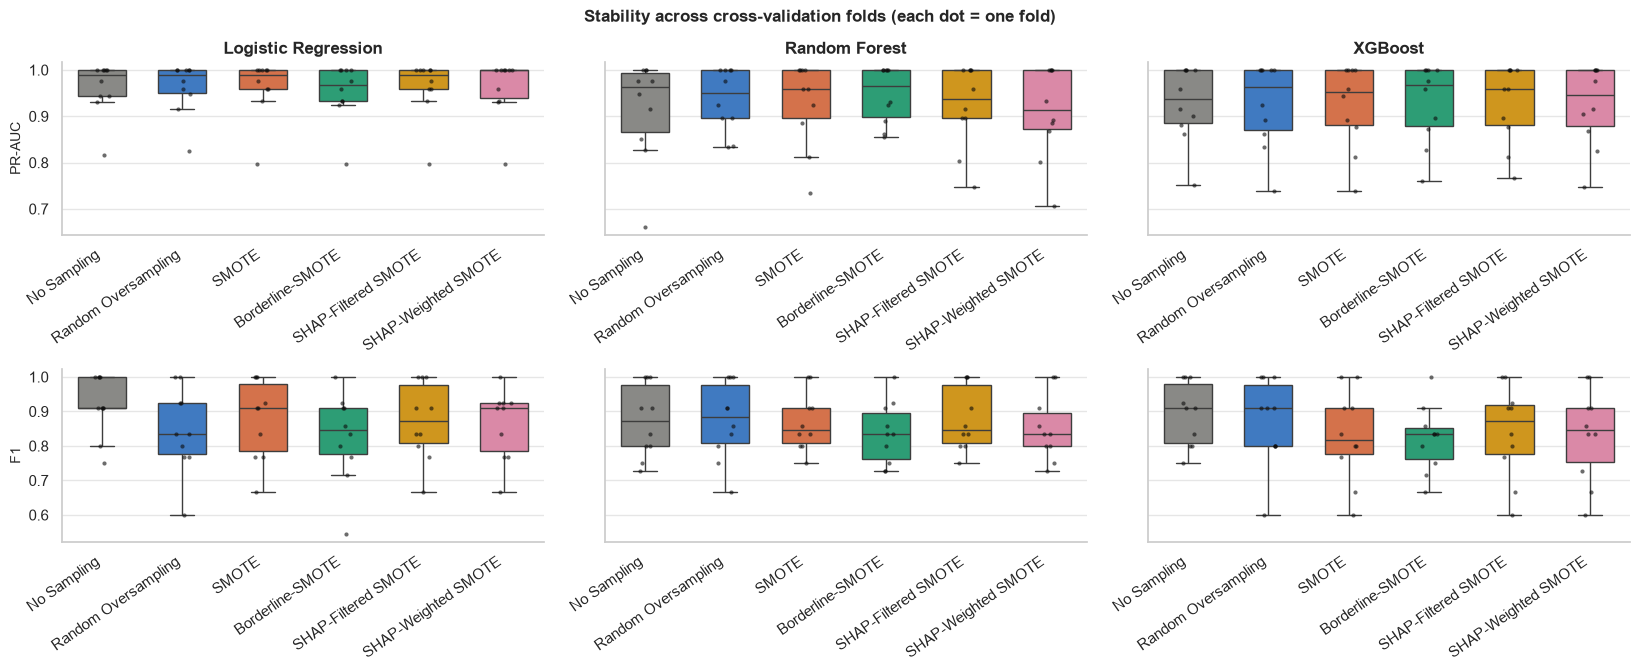

In [18]:
PL.performance_comparison(cv, PLOTS); plt.show()
PL.fold_distributions(cv, PLOTS); plt.show()

In [19]:
tests = R.paired_tests(cv)
display(Markdown("**Wilcoxon signed-rank tests vs SMOTE, paired by fold** (two-sided; p < 0.05 marked)"))
display(tests[tests.method.isin(C.PROPOSED_METHODS)].style.format({"mean_difference": "{:+.4f}", "p_value": "{:.3f}"})
        .apply(lambda r: ["font-weight: bold" if r.p_value < 0.05 else "" for _ in r], axis=1))

**Wilcoxon signed-rank tests vs SMOTE, paired by fold** (two-sided; p < 0.05 marked)

,model,method,vs,metric,mean_difference,folds_better,folds_worse,p_value
12,Logistic Regression,SHAP-Filtered SMOTE,SMOTE,PR-AUC,+0.0000,0,0,1.000
13,Logistic Regression,SHAP-Filtered SMOTE,SMOTE,F1,-0.0059,1,1,1.000
14,Logistic Regression,SHAP-Filtered SMOTE,SMOTE,Recall,+0.0000,0,0,1.000
15,Logistic Regression,SHAP-Filtered SMOTE,SMOTE,Precision,-0.0071,1,1,1.000
16,Logistic Regression,SHAP-Weighted SMOTE,SMOTE,PR-AUC,-0.0004,1,1,1.000
17,Logistic Regression,SHAP-Weighted SMOTE,SMOTE,F1,-0.0154,0,2,0.500
18,Logistic Regression,SHAP-Weighted SMOTE,SMOTE,Recall,+0.0000,0,0,1.000
19,Logistic Regression,SHAP-Weighted SMOTE,SMOTE,Precision,-0.0286,0,2,0.500
32,Random Forest,SHAP-Filtered SMOTE,SMOTE,PR-AUC,-0.0055,3,3,0.844
33,Random Forest,SHAP-Filtered SMOTE,SMOTE,F1,+0.0091,1,1,1.000


## Stage 6: Hold-out test evaluation
The models fitted in Stage 4 on the (resampled) development set are scored **once** on the untouched 25% test
set, at the 0.5 decision threshold. Test-set rankings rest on a single split and few minority cases, so read them
together with the cross-validation results in Stage 5.

In [20]:
for model in C.MODEL_ORDER:
    display(Markdown(f"**{model}: hold-out test set**"))
    display(S.comparison_table(final, model).style.format("{:.4f}").highlight_max(axis=0, props="font-weight: bold"))
cm = final.test_metrics.set_index(["model", "method"])[["tn", "fp", "fn", "tp", "brier", "ece"]]
display(Markdown("**Confusion-matrix counts and calibration (Brier score, ECE) on the test set**"))
display(cm)

**Logistic Regression: hold-out test set**

,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,Specificity
Sampling Method,,,,,,,
No Sampling,0.9899,1.0000,0.9000,0.9474,0.9989,0.9909,1.0000
Random Oversampling,0.9899,1.0000,0.9000,0.9474,0.9955,0.9714,1.0000
SMOTE,0.9899,1.0000,0.9000,0.9474,0.9989,0.9909,1.0000
Borderline-SMOTE,0.9899,1.0000,0.9000,0.9474,0.9944,0.9667,1.0000
SHAP-Filtered SMOTE,0.9899,1.0000,0.9000,0.9474,0.9978,0.9833,1.0000
SHAP-Weighted SMOTE,0.9899,1.0000,0.9000,0.9474,0.9978,0.9833,1.0000


**Random Forest: hold-out test set**

,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,Specificity
Sampling Method,,,,,,,
No Sampling,0.9798,1.0000,0.8000,0.8889,0.9989,0.9909,1.0000
Random Oversampling,0.9899,1.0000,0.9000,0.9474,0.9989,0.9909,1.0000
SMOTE,0.9798,1.0000,0.8000,0.8889,0.9989,0.9909,1.0000
Borderline-SMOTE,0.9798,1.0000,0.8000,0.8889,0.9944,0.9667,1.0000
SHAP-Filtered SMOTE,0.9798,1.0000,0.8000,0.8889,0.9989,0.9909,1.0000
SHAP-Weighted SMOTE,0.9798,1.0000,0.8000,0.8889,0.9989,0.9909,1.0000


**XGBoost: hold-out test set**

,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,Specificity
Sampling Method,,,,,,,
No Sampling,0.9899,1.0000,0.9000,0.9474,1.0000,1.0000,1.0000
Random Oversampling,0.9899,1.0000,0.9000,0.9474,0.9978,0.9833,1.0000
SMOTE,0.9899,1.0000,0.9000,0.9474,1.0000,1.0000,1.0000
Borderline-SMOTE,0.9798,0.9000,0.9000,0.9000,0.9989,0.9909,0.9888
SHAP-Filtered SMOTE,0.9899,1.0000,0.9000,0.9474,1.0000,1.0000,1.0000
SHAP-Weighted SMOTE,0.9899,1.0000,0.9000,0.9474,1.0000,1.0000,1.0000


**Confusion-matrix counts and calibration (Brier score, ECE) on the test set**

,,tn,fp,fn,tp,brier,ece
model,method,,,,,,
Logistic Regression,No Sampling,89,0,1,9,0.0111,0.0286
Random Forest,No Sampling,89,0,2,8,0.0141,0.0349
XGBoost,No Sampling,89,0,1,9,0.0101,0.0235
Logistic Regression,Random Oversampling,89,0,1,9,0.0109,0.0202
Random Forest,Random Oversampling,89,0,1,9,0.0166,0.0402
XGBoost,Random Oversampling,89,0,1,9,0.0117,0.0231
Logistic Regression,SMOTE,89,0,1,9,0.0092,0.0269
Random Forest,SMOTE,89,0,2,8,0.0126,0.0322
XGBoost,SMOTE,89,0,1,9,0.0064,0.0182


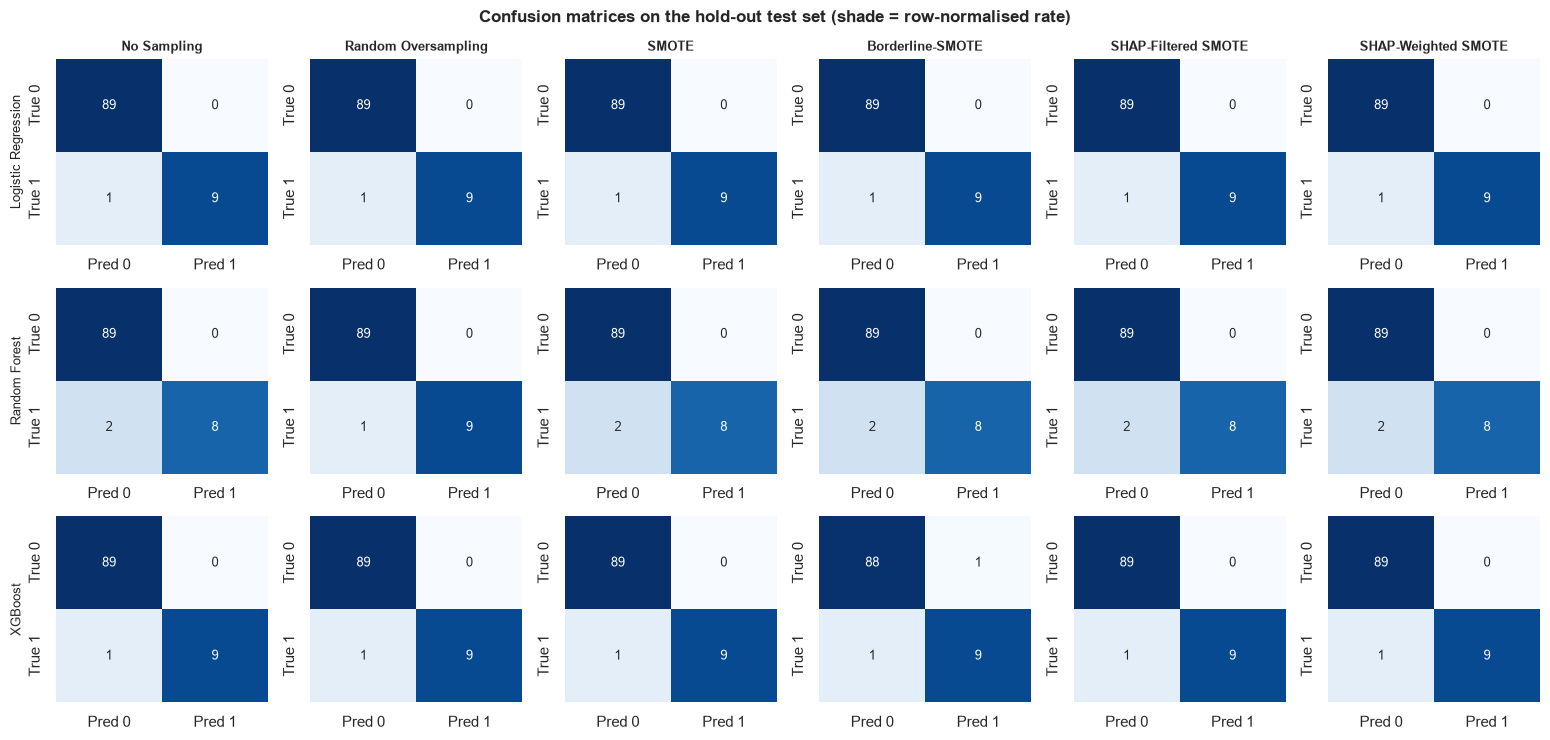

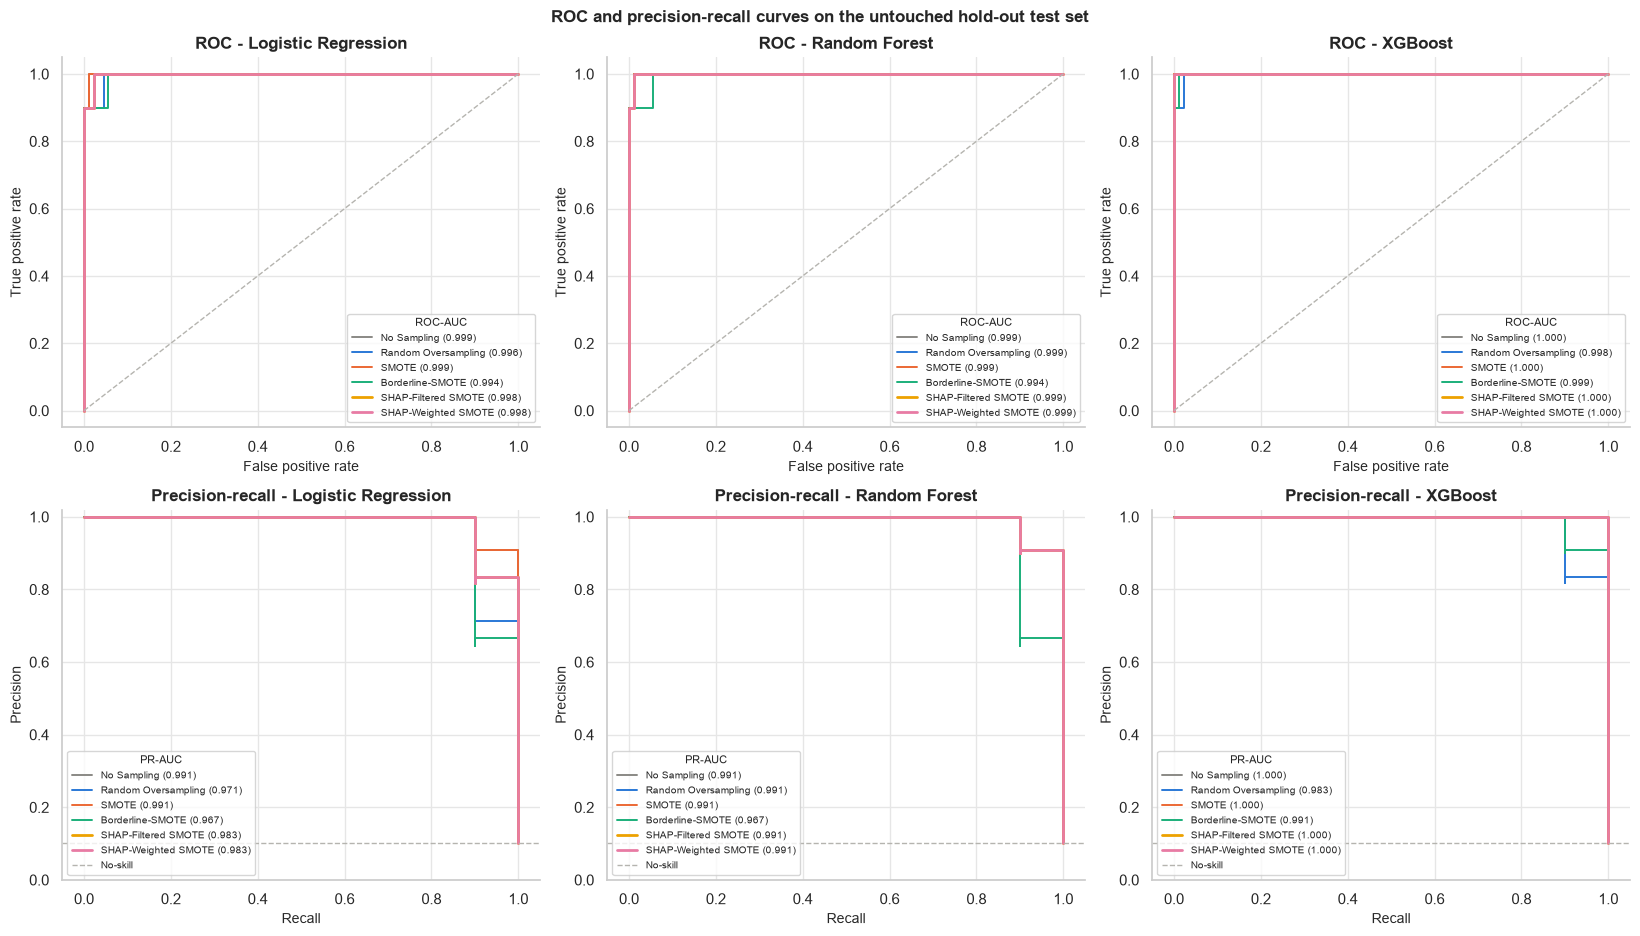

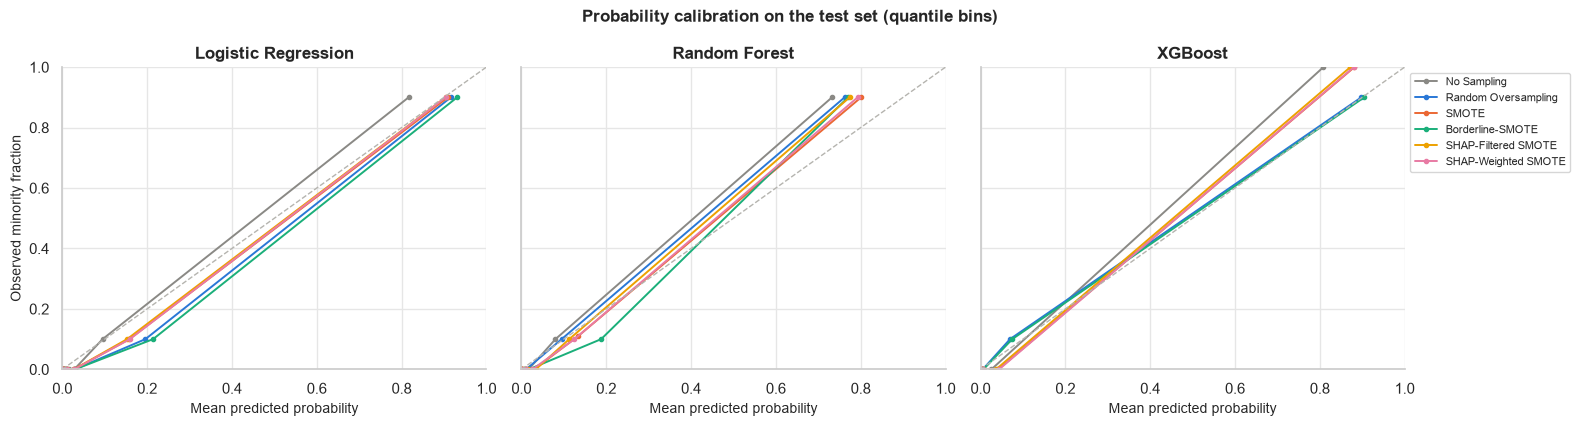

In [21]:
PL.confusion_matrices(final, PLOTS); plt.show()
PL.roc_pr_curves(final, PLOTS); plt.show()
PL.calibration_curves(final, PLOTS); plt.show()

## Stage 7: SHAP explainability comparison
Do the final models rely on different features depending on how their training data was balanced? Each final
model is explained on the same test rows (all minority rows up to 250, plus majority rows up to 500 in total).
Logistic Regression uses `LinearExplainer` with a training background; the tree models use `TreeExplainer`.
Across CV folds, the stability of each model's SHAP feature ranking is measured with Kendall τ.

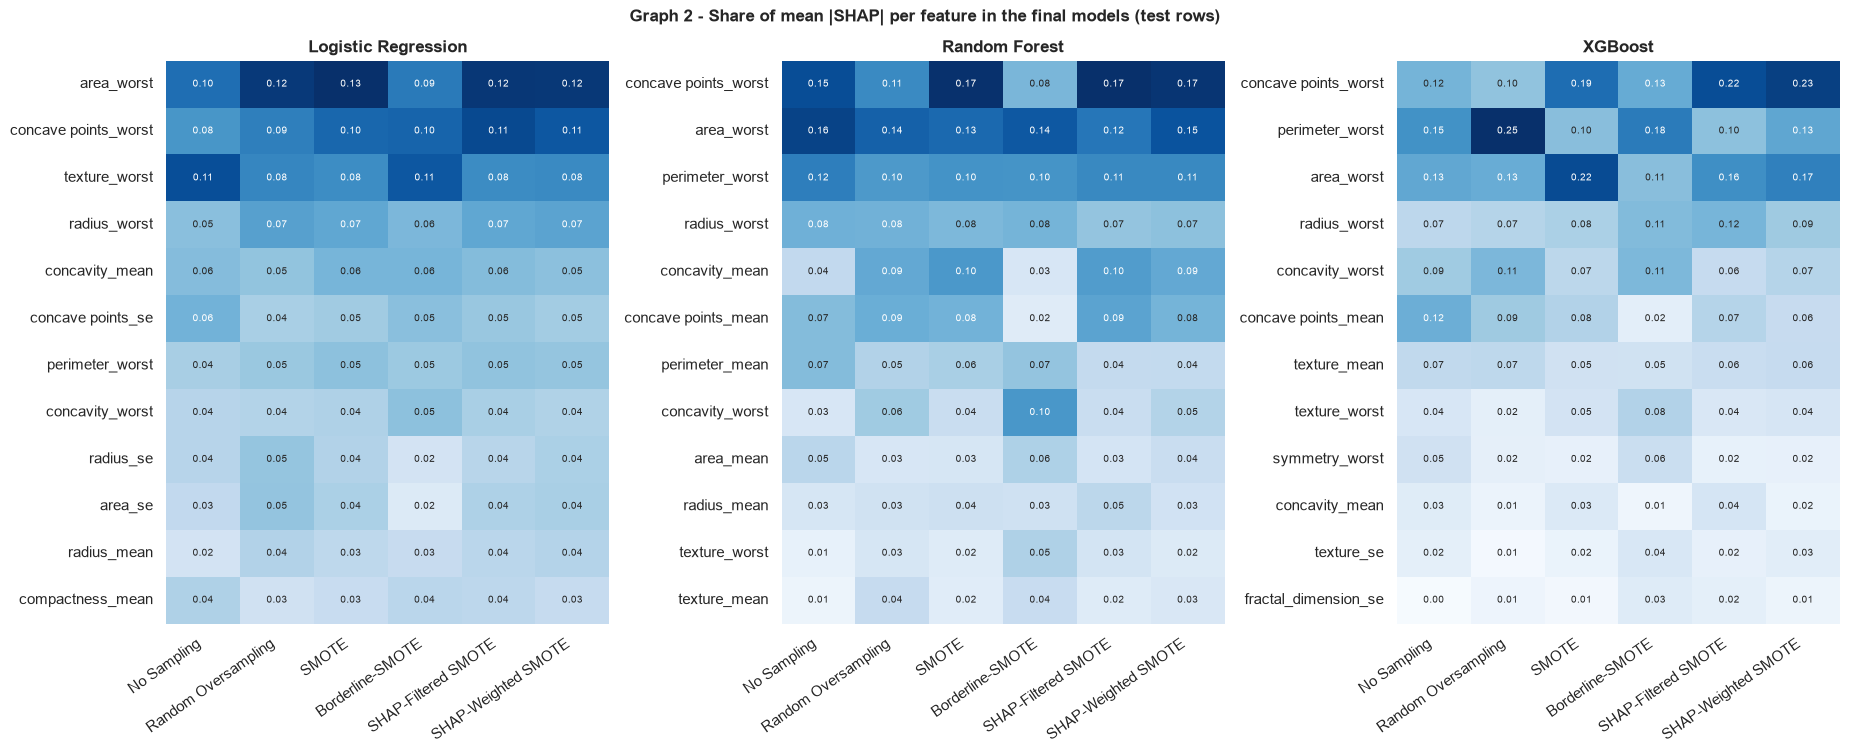

**Spearman correlation of each final model's feature-importance vector with the No Sampling model**

,Logistic Regression,Random Forest,XGBoost
No Sampling,1.0000,1.0000,1.0000
Random Oversampling,0.7339,0.8799,0.8319
SMOTE,0.9164,0.9199,0.7515
Borderline-SMOTE,0.7971,0.7050,0.8267
SHAP-Filtered SMOTE,0.9212,0.8941,0.7946
SHAP-Weighted SMOTE,0.8874,0.8701,0.7556


In [22]:
PL.shap_explainability_comparison(final, PLOTS); plt.show()
rank_corr = pd.DataFrame({model: final.importance_table(model).T.corr(method="spearman")["No Sampling"]
                          for model in C.MODEL_ORDER})
display(Markdown("**Spearman correlation of each final model's feature-importance vector with the No Sampling model**"))
display(rank_corr)

,,kendall_tau_mean,kendall_tau_std,spearman_rho_mean,spearman_rho_std,top_k_overlap
model,method,,,,,
Logistic Regression,No Sampling,0.5461,0.1176,0.7208,0.1159,0.5016
Random Forest,No Sampling,0.7275,0.0426,0.8812,0.0318,0.7693
XGBoost,No Sampling,0.5922,0.1142,0.7466,0.1173,0.6235
Logistic Regression,Random Oversampling,0.5382,0.1400,0.7059,0.1393,0.7746
Random Forest,Random Oversampling,0.7630,0.0522,0.9144,0.0349,0.7011
XGBoost,Random Oversampling,0.5842,0.1039,0.7598,0.1028,0.5942
Logistic Regression,SMOTE,0.5819,0.1084,0.7566,0.1043,0.5947
Random Forest,SMOTE,0.7601,0.0405,0.9089,0.0254,0.7587
XGBoost,SMOTE,0.5949,0.0968,0.7685,0.0964,0.6582


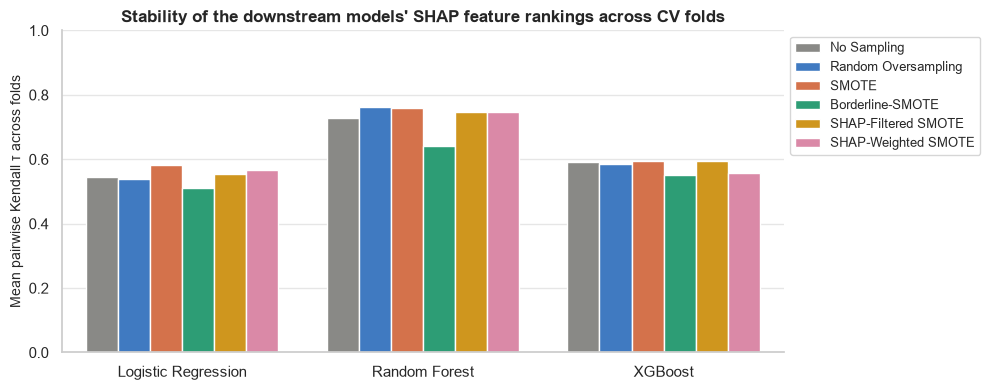

In [23]:
stability = R.attribution_stability(cv)
display(stability)
PL.attribution_stability_plot(stability, PLOTS); plt.show()

## Stage 8: Saved outputs and summary
Every table and figure is saved under `results/<dataset>/` (same layout for all datasets):
`metrics/`, `synthetic_samples/`, `neighbour_analysis/` and `plots/`.

In [24]:
saved = O.save_metrics(DIRS, dev_df, test_df, cv, final, stability, tests, quality_tbl)
display(saved)
print("plots:", ", ".join(sorted(p.name for p in PLOTS.glob("*.png"))))

,file
0,results/breast_cancer/metrics/split_assignment...
1,results/breast_cancer/metrics/cv_fold_metrics.csv
2,results/breast_cancer/metrics/cv_mean_metrics.csv
3,results/breast_cancer/metrics/cv_summary_mean_...
4,results/breast_cancer/metrics/cv_sampling_runt...
5,results/breast_cancer/metrics/test_metrics.csv
6,results/breast_cancer/metrics/final_sampling_c...
7,results/breast_cancer/metrics/attribution_stab...
8,results/breast_cancer/metrics/paired_tests_vs_...
9,results/breast_cancer/metrics/synthetic_qualit...


plots: 01_class_distribution.png, 02_feature_distributions.png, 03_correlation_heatmap.png, 04_class_comparison.png, 05_balanced_class_counts.png, 06_shap_feature_weights.png, 07_shap_summary_preliminary_model.png, 08_pca_original_vs_synthetic.png, 09_synthetic_feature_distributions.png, 10_graph1_performance_comparison.png, 11_cv_fold_stability.png, 12_roc_pr_curves.png, 13_confusion_matrices.png, 14_calibration_curves.png, 15_graph2_shap_explainability_comparison.png, 16_attribution_stability.png


### Final summary
Numbers below are computed from this run, not typed by hand.

In [25]:
display(Markdown(f"**Dataset:** {spec.title}, {len(df):,} rows, {len(spec.features)} raw features "
                 f"({len(pre.feature_names_)} model columns after encoding)."))
display(D.overview(df, spec))
display(Markdown("**Preprocessing:** stratified 75/25 development/test split; median / most-frequent imputation, "
                 "one-hot encoding and standard scaling fitted on training rows only; oversampling only inside "
                 "training folds."))
display(Markdown("**Oversampling results (final development-set fit):**"))
display(final.sampling.join(quality_tbl.reindex(columns=["majority_share_in_5nn", "mean_wasserstein_distance",
                                          "correlation_matrix_similarity", "detectability_auc_all", "detectability_auc_numeric"]), how="left"))
display(Markdown("**SHAP-guided vs SMOTE (CV mean difference, Wilcoxon p-value):**"))
display(S.dataset_findings(cv, tests, quality_tbl).T)
display(Markdown("**Findings derived from the numbers:**\n" + "\n".join(f"- {l}" for l in S.findings_text(cv, tests, quality_tbl))))

**Dataset:** Breast Cancer Wisconsin (Diagnostic), 396 rows, 30 raw features (30 model columns after encoding).

,Domain,Rows,Numeric features,Categorical features,Majority (0),Minority (1),Minority %,Imbalance ratio,Minority:majority
Dataset,,,,,,,,,
Breast Cancer Wisconsin (Diagnostic),Medical diagnosis,396,30,0,357,39,9.85%,9.2 : 1,1 : 9.2


**Preprocessing:** stratified 75/25 development/test split; median / most-frequent imputation, one-hot encoding and standard scaling fitted on training rows only; oversampling only inside training folds.

**Oversampling results (final development-set fit):**

,real_majority,real_minority,synthetic_minority,final_majority,final_minority,sampling_seconds,majority_share_in_5nn,mean_wasserstein_distance,correlation_matrix_similarity,detectability_auc_all,detectability_auc_numeric
method,,,,,,,,,,,
No Sampling,268,29,0,268,29,0.0108,NaN,NaN,NaN,NaN,NaN
Random Oversampling,268,29,239,268,268,1.4695,0.1632,0.0595,0.9961,NaN,NaN
SMOTE,268,29,239,268,268,0.0598,0.1213,0.1864,0.9821,0.5258,0.5258
Borderline-SMOTE,268,29,239,268,268,0.0630,0.3615,0.6074,0.7080,0.7556,0.7556
SHAP-Filtered SMOTE,268,29,239,268,268,0.3120,0.1238,0.1748,0.9788,0.5172,0.5172
SHAP-Weighted SMOTE,268,29,239,268,268,0.3156,0.1280,0.1794,0.9843,0.5362,0.5362


**SHAP-guided vs SMOTE (CV mean difference, Wilcoxon p-value):**

model,Logistic Regression,Random Forest,XGBoost
best PR-AUC,Random Oversampling (0.963),Borderline-SMOTE (0.946),Borderline-SMOTE (0.929)
best F1,No Sampling (0.919),SHAP-Filtered SMOTE (0.878),No Sampling (0.892)
best recall,Random Oversampling (0.910),SMOTE (0.843),No Sampling (0.843)
SHAP-F - SMOTE PR-AUC,+0.000 (p=1.00),-0.006 (p=0.84),+0.004 (p=0.31)
SHAP-F - SMOTE F1,-0.006 (p=1.00),+0.009 (p=1.00),+0.012 (p=1.00)
SHAP-F - SMOTE Recall,+0.000 (p=1.00),+0.000 (p=1.00),+0.000 (p=1.00)
SHAP-F - SMOTE Precision,-0.007 (p=1.00),+0.012 (p=1.00),+0.019 (p=1.00)
SHAP-W - SMOTE PR-AUC,-0.000 (p=1.00),-0.019 (p=0.06),+0.002 (p=0.56)
SHAP-W - SMOTE F1,-0.015 (p=0.50),-0.018 (p=1.00),+0.005 (p=1.00)
SHAP-W - SMOTE Recall,+0.000 (p=1.00),-0.017 (p=1.00),+0.000 (p=1.00)


**Findings derived from the numbers:**
- Logistic Regression: PR-AUC ranking = Random Oversampling 0.963 > SMOTE 0.962 > SHAP-Filtered SMOTE 0.962 > SHAP-Weighted SMOTE 0.962 > No Sampling 0.961 > Borderline-SMOTE 0.952
-   SHAP-Filtered SMOTE vs SMOTE: PR-AUC +0.000 (0/0 folds better, p=1.000, not significant); F1 -0.006 (1/2 folds better, p=1.000, not significant); Recall +0.000 (0/0 folds better, p=1.000, not significant); Precision -0.007 (1/2 folds better, p=1.000, not significant)
-   SHAP-Weighted SMOTE vs SMOTE: PR-AUC -0.000 (1/2 folds better, p=1.000, not significant); F1 -0.015 (0/2 folds better, p=0.500, not significant); Recall +0.000 (0/0 folds better, p=1.000, not significant); Precision -0.029 (0/2 folds better, p=0.500, not significant)
- Random Forest: PR-AUC ranking = Borderline-SMOTE 0.946 > Random Oversampling 0.936 > SMOTE 0.927 > SHAP-Filtered SMOTE 0.922 > No Sampling 0.916 > SHAP-Weighted SMOTE 0.909
-   SHAP-Filtered SMOTE vs SMOTE: PR-AUC -0.006 (3/6 folds better, p=0.844, not significant); F1 +0.009 (1/2 folds better, p=1.000, not significant); Recall +0.000 (0/0 folds better, p=1.000, not significant); Precision +0.012 (1/2 folds better, p=1.000, not significant)
-   SHAP-Weighted SMOTE vs SMOTE: PR-AUC -0.019 (1/6 folds better, p=0.062, not significant); F1 -0.018 (0/1 folds better, p=1.000, not significant); Recall -0.017 (0/1 folds better, p=1.000, not significant); Precision -0.020 (0/1 folds better, p=1.000, not significant)
- XGBoost: PR-AUC ranking = Borderline-SMOTE 0.929 > No Sampling 0.927 > SHAP-Filtered SMOTE 0.927 > Random Oversampling 0.925 > SHAP-Weighted SMOTE 0.924 > SMOTE 0.922
-   SHAP-Filtered SMOTE vs SMOTE: PR-AUC +0.004 (3/5 folds better, p=0.312, not significant); F1 +0.012 (1/1 folds better, p=1.000, not significant); Recall +0.000 (0/0 folds better, p=1.000, not significant); Precision +0.019 (1/1 folds better, p=1.000, not significant)
-   SHAP-Weighted SMOTE vs SMOTE: PR-AUC +0.002 (4/6 folds better, p=0.562, not significant); F1 +0.005 (2/3 folds better, p=1.000, not significant); Recall +0.000 (0/0 folds better, p=1.000, not significant); Precision -0.003 (2/3 folds better, p=1.000, not significant)
- Synthetic rows' majority share among 5 nearest real rows (lower = less overlap): Real minority (reference) 0.221, Random Oversampling 0.163, SMOTE 0.121, Borderline-SMOTE 0.362, SHAP-Filtered SMOTE 0.124, SHAP-Weighted SMOTE 0.128
- Mean marginal Wasserstein distance synthetic vs real minority (lower = closer): Random Oversampling 0.059, SMOTE 0.186, Borderline-SMOTE 0.607, SHAP-Filtered SMOTE 0.175, SHAP-Weighted SMOTE 0.179
- Correlation-structure similarity synthetic vs real minority (1 = identical): Random Oversampling 0.996, SMOTE 0.982, Borderline-SMOTE 0.708, SHAP-Filtered SMOTE 0.979, SHAP-Weighted SMOTE 0.984
- Real-vs-synthetic detectability AUC, all columns / numeric only (0.5 = indistinguishable): SMOTE 0.526 / 0.526, Borderline-SMOTE 0.756 / 0.756, SHAP-Filtered SMOTE 0.517 / 0.517, SHAP-Weighted SMOTE 0.536 / 0.536

### Interpretation: Breast Cancer Wisconsin (9.2 : 1)

**Which method performed best?** No method stands out. The minority class (39 malignant cases, 29 in the
development set) is well separated: ROC-AUC is ≥ 0.96 for every method and model in cross-validation. The best
CV PR-AUC is Random Oversampling with Logistic Regression (0.962, tied with SMOTE and both SHAP methods) and
Borderline-SMOTE with the tree models (Random Forest 0.946, XGBoost 0.929). The best CV F1 is **No Sampling**
with Logistic Regression (0.919) and XGBoost (0.892): at 9:1 with clean separation, oversampling mainly trades
precision for a little recall.

**Did SHAP-guided SMOTE improve minority-class detection?** No. Recall is identical to SMOTE for both SHAP methods
with Logistic Regression and XGBoost, and 0.017 lower for SHAP-Weighted SMOTE with Random Forest. On the hold-out
test set (10 malignant cases), every SMOTE-family method catches the same 8–9 cases.

**PR-AUC and F1?** The differences from SMOTE are within ±0.02 and none is statistically significant (Wilcoxon,
10 paired folds). The closest to significance is SHAP-Weighted SMOTE with Random Forest, which is *worse* than
SMOTE on PR-AUC (−0.019, worse in 5 of the 6 folds that differ, p = 0.06).

**Precision?** Mixed and small: SHAP-Filtered SMOTE is slightly more precise than SMOTE with the tree models
(+0.012 RF, +0.019 XGBoost); SHAP-Weighted SMOTE is slightly less precise with Logistic Regression and Random
Forest (−0.03 and −0.02). None of these is significant.

**Did the synthetic samples preserve feature relationships?** Yes, for SMOTE and both SHAP methods: correlation-matrix
similarity to the real minority is 0.98, every feature passes the KS test, and synthetic rows sit in minority
territory (12–13% majority among their 5 nearest real rows, below the 22% of the real minority rows themselves),
and a Random Forest can barely tell them from real malignant cases (detectability AUC 0.52–0.54, 0.5 = indistinguishable).
SHAP guidance changed the pairing (mean Jaccard similarity with SMOTE's neighbour sets only 0.61–0.69, and parent pairs with more similar
SHAP explanations: cosine 0.85–0.86 vs 0.84), but the resulting samples are statistically very close to SMOTE's.
Borderline-SMOTE is the outlier: all its samples come from the 7 DANGER rows, so they are pushed toward the
boundary (36% majority neighbours), distort the correlation structure (similarity 0.71, 43% of features pass
the KS test) and are easy to detect (AUC 0.76).

**Where did SHAP-guided SMOTE fail or underperform?** It brought no measurable gain on an easy, low-dimensional,
moderately imbalanced problem where plain Euclidean neighbours are already sensible. SHAP-Weighted SMOTE with
Random Forest is the weakest SMOTE variant here (CV PR-AUC 0.909 vs 0.927 for SMOTE). The small minority count
(10 test cases, about 6 per validation fold) also limits what any comparison can resolve.